# Customer Data Analysis & Insights Using Python

**Role:** Senior Data Analyst | **Tools:** Python, Pandas, NumPy, Matplotlib, Excel

## Business problem
An online gift retailer (UK-based, many wholesale customers) wants to know **who its customers are, how they buy, which ones create the most value and which ones are about to be lost** - so that marketing and account management can focus on the right people.

## Data
**Real data:** the public UCI *Online Retail* dataset (541,909 transaction lines, 1 Dec 2010 - 9 Dec 2011, licence CC BY 4.0). See `data/raw/DATA_SOURCE.md` for the source, structure and limitations. Nothing in this project is synthetic.

## Workflow
1. Inspect the raw data and list its problems
2. Clean it with `src/data_cleaning.py` (every row is accounted for)
3. Exploratory analysis: customers, orders, revenue, trends, repeat behaviour, concentration, retention
4. RFM segmentation and back-test
5. Business insights and recommendations
6. Export: segments CSV, Excel workbook, results JSON (used by the PDF report)
7. Independent checks of the numbers

> The code is in `src/` (cleaning, RFM, metrics, charts, insights); this notebook runs it step by step and explains each decision.

## 0. Setup

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import customer_metrics as cm
import data_cleaning as dc
import excel_export as xl
import insights as ins
import rfm_analysis as ra
import visualization as viz

PROCESSED = ROOT / "data" / "processed"
VIZ = ROOT / "visualizations"
OUT = ROOT / "outputs"
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.width", 200)
print("Project root:", ROOT)
print("pandas", pd.__version__, "| numpy", np.__version__)

Project root: /home/claude/customer-data-analysis
pandas 3.0.5 | numpy 2.5.3


## 1. Raw data inspection
The raw file is read exactly as it is (IDs as text) and never modified.

In [2]:
raw = dc.load_raw(ROOT / "data" / "raw" / "online_retail_raw.csv")
print("Shape:", raw.shape)
display(raw.head())
raw.info()

Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,"17,850.00",United Kingdom


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  string 
 1   StockCode    541909 non-null  string 
 2   Description  540455 non-null  string 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  string 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  string 
dtypes: float64(2), int64(1), string(5)
memory usage: 33.1 MB


### What is wrong with the raw data?
Each check below is a question a business user would ask: *can I trust these rows?*

In [3]:
std = dc._standardise(raw)
checks = pd.DataFrame({
    "check": [
        "Rows with no CustomerID (guest)",
        "Rows with no Description",
        "Exact duplicate rows",
        "Cancellation invoices (InvoiceNo starts with C)",
        "Rows with UnitPrice <= 0",
        "Rows with Quantity < 0 that are NOT cancellations",
        "Non-product StockCodes (POST, DOT, M, D, BANK CHARGES ...)",
    ],
    "rows": [
        int(raw["CustomerID"].isna().sum()),
        int(raw["Description"].isna().sum()),
        int(raw.duplicated().sum()),
        int(std["IsCancellation"].sum()),
        int((raw["UnitPrice"] <= 0).sum()),
        int(((raw["Quantity"] < 0) & ~std["IsCancellation"]).sum()),
        int(raw["StockCode"].str.upper().isin(dc.NON_PRODUCT_CODES.keys()).sum()),
    ],
})
checks["% of rows"] = 100 * checks["rows"] / len(raw)
display(checks)
print("InvoiceDate range:", std["InvoiceDate"].min(), "->", std["InvoiceDate"].max())
print("Date format check: largest first number =", raw["InvoiceDate"].str.split("/").str[0].astype(int).max(),
      "| largest second number =", raw["InvoiceDate"].str.split("/").str[1].astype(int).max(),
      "-> the format is month/day/year")

,check,rows,% of rows
0,Rows with no CustomerID (guest),135080,24.93
1,Rows with no Description,1454,0.27
2,Exact duplicate rows,5268,0.97
3,Cancellation invoices (InvoiceNo starts with C),9288,1.71
4,Rows with UnitPrice <= 0,2517,0.46
5,Rows with Quantity < 0 that are NOT cancellations,1336,0.25
6,"Non-product StockCodes (POST, DOT, M, D, BANK CHARGES ...)",2916,0.54


InvoiceDate range: 2010-12-01 08:26:00 -> 2011-12-09 12:50:00
Date format check: largest first number = 12 | largest second number = 31 -> the format is month/day/year


**Findings**
* 24.9% of rows have no `CustomerID`: they cannot be used for customer analysis. (The UCI page says the data has no missing values - the file proves otherwise.)
* Cancellations are separate negative rows that cannot be linked to the original invoice.
* Some rows are not merchandise at all (postage, bank charges, manual entries) and some have price 0 (stock write-offs).
* Two customers have enormous orders that were cancelled almost immediately - the largest "outliers" in the data are not real demand.

## 2. Data cleaning
`dc.clean_transactions()` puts **every raw row into exactly one bucket** (first matching rule wins), so nothing disappears silently.

| Rule | Reason | Business impact |
|---|---|---|
| 1. Exact duplicate rows | Same invoice line recorded twice | Would double-count revenue |
| 2. Non-product StockCodes | Postage, fees, adjustments are not purchases of goods | Would inflate frequency and spend |
| 3. UnitPrice <= 0 | Stock write-offs ("damaged", "lost"), not sales | Would add fake orders at £0 |
| 4. Cancellations with a customer | **Kept** as returns and netted against spend | Customer value = sales - returns |
| 5. Cancellations without a customer | Cannot be assigned | Excluded and counted |
| 6. Sales without a customer | Guest rows | Excluded from customer analysis, reported separately |

In [4]:
result = dc.clean_transactions(raw)
paths = dc.save_outputs(result, PROCESSED)
sales, returns = result.sales, result.returns
display(result.log)

,bucket,description,rows,pct_of_raw_rows,value_gbp
0,exact_duplicate,Exact duplicate rows removed,5268,0.97,"21,740.98"
1,non_product_code,"Non-product lines (postage, fees, manual, discount, bad debt)",2910,0.54,"-45,997.02"
2,zero_or_negative_price,Zero / negative price lines (stock write-offs),2495,0.46,0.00
3,return_without_customer,Returns without a customer,162,0.03,"-4,150.45"
4,sale_without_customer,Sales without a customer (guest),131418,24.25,"1,510,677.49"
5,return_kept_for_netting,Returns kept (netted against customer spend),8506,1.57,"-471,750.71"
6,clean_sale,Clean customer sales (analysis base),391150,72.18,"8,737,227.64"
7,TOTAL,All raw rows,541909,100.00,"9,747,747.93"


In [5]:
display(result.quality_report)

,check,raw_data,clean_sales
0,Rows,541909,391150
1,Missing CustomerID,135080,0
2,Missing Description,1454,0
3,Exact duplicate rows,5268,0
4,Quantity <= 0,10624,0
5,UnitPrice <= 0,2517,0
6,Cancellation invoices (rows),9288,0
7,Unique customers,4372,4334
8,Unique invoices,25900,18402


### Reconciliation
The buckets must add up to the raw file, both in rows and in money.

In [6]:
tot = result.log[result.log["bucket"] == "TOTAL"].iloc[0]
assert tot["rows"] == len(raw), "rows do not reconcile"
assert abs(tot["value_gbp"] - (raw["Quantity"] * raw["UnitPrice"]).sum()) < 1, "value does not reconcile"
print(f"OK - {len(raw):,} raw rows = sum of buckets. Total raw value £{tot['value_gbp']:,.2f}")
print("Guest sales (excluded from customer analysis): £{:,.2f}, {:.1f}% of all sale value".format(
    result.guest_sales["Revenue"].sum(), 100 * result.guest_sales["Revenue"].sum() / (sales["Revenue"].sum() + result.guest_sales["Revenue"].sum())))

OK - 541,909 raw rows = sum of buckets. Total raw value £9,747,747.93
Guest sales (excluded from customer analysis): £1,510,677.49, 14.7% of all sale value


### Outliers: the two giant cancelled orders
Outliers are not removed because they are large - they are handled because we can show what they are. Two customers placed a huge order and cancelled it. Because returns are netted, **their net value becomes zero**; deleting them by a statistical rule would have been wrong for everyone else.

In [7]:
giant = sales.sort_values("Revenue", ascending=False).head(3)[["InvoiceNo", "CustomerID", "Description", "Quantity", "UnitPrice", "Revenue", "InvoiceDate"]]
display(giant)
big_ids = giant["CustomerID"].unique()
display(returns[returns["CustomerID"].isin(big_ids)].sort_values("Revenue").head(3)[["InvoiceNo", "CustomerID", "Description", "Quantity", "Revenue", "InvoiceDate"]])

,InvoiceNo,CustomerID,Description,Quantity,UnitPrice,Revenue,InvoiceDate
390689,581483,16446,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,"168,469.60",2011-12-09 09:15:00
36375,541431,12346,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,"77,183.60",2011-01-18 10:01:00
152957,556444,15098,PICNIC BASKET WICKER 60 PIECES,60,649.50,"38,970.00",2011-06-10 15:28:00


,InvoiceNo,CustomerID,Description,Quantity,Revenue,InvoiceDate
8500,C581484,16446,"PAPER CRAFT , LITTLE BIRDIE",-80995,"-168,469.60",2011-12-09 09:27:00
959,C541433,12346,MEDIUM CERAMIC TOP STORAGE JAR,-74215,"-77,183.60",2011-01-18 10:17:00
3653,C556448,15098,PICNIC BASKET WICKER SMALL,-60,-297.00,2011-06-10 15:39:00


## 3. Customer table
One row per customer: first/last purchase, recency, frequency (distinct invoices), gross revenue, returns, **net revenue**, average order value. The snapshot date is the day after the last transaction (10 Dec 2011), so a customer who bought on the last day has recency 1.

In [8]:
snapshot = ra.snapshot_date(sales)
cust = ra.build_customer_table(sales, returns, snapshot)
print("Snapshot date:", snapshot.date(), "| customers:", len(cust))
display(cust.head())

Snapshot date: 2011-12-10 | customers: 4334


,CustomerID,first_purchase,last_purchase,frequency,gross_revenue,recency_days,units,distinct_products,country,return_value,net_revenue,avg_order_value,return_rate_pct,tenure_days,active_months
0,12346,2011-01-18 10:01:00,2011-01-18 10:01:00,1,"77,183.60",326,74215,1,United Kingdom,"77,183.60",0.00,"77,183.60",100.00,0,1
1,12347,2010-12-07 14:57:00,2011-12-07 15:52:00,7,"4,310.00",3,2458,103,Iceland,0.00,"4,310.00",615.71,0.00,365,7
2,12348,2010-12-16 19:09:00,2011-09-25 13:13:00,4,"1,437.24",76,2332,21,Finland,0.00,"1,437.24",359.31,0.00,283,4
3,12349,2011-11-21 09:51:00,2011-11-21 09:51:00,1,"1,457.55",19,630,72,Italy,0.00,"1,457.55","1,457.55",0.00,0,1
4,12350,2011-02-02 16:01:00,2011-02-02 16:01:00,1,294.40,311,196,16,Norway,0.00,294.40,294.40,0.00,0,1


## 4. Exploratory analysis
### 4.1 Headline KPIs

In [9]:
kpis = cm.headline_kpis(sales, returns, cust)
display(pd.Series(kpis, name="value").to_frame())

,value
period_start,2010-12-01
period_end,2011-12-09
customers,4334
orders,18402
gross_revenue,"8,737,227.64"
returns_value,"471,750.71"
net_revenue,"8,265,476.93"
return_rate_pct,5.40
avg_order_value,474.80
net_avg_order_value,449.16


Note on **average order value**: returns cannot be matched to the invoice they cancel, so AOV is shown before returns (`avg_order_value`) and after (`net_avg_order_value`). The **median** order is much lower than the mean because a few very large wholesale orders stretch the average.

### 4.2 Monthly trends

,month,orders,active_customers,new_customers,returning_customers,gross_revenue,returns_value,net_revenue,avg_order_value,is_partial
0,2010-12,1394,884,884,0,"565,199.56","17,305.64","547,893.92",405.45,False
1,2011-01,983,739,416,323,"562,682.91","91,252.57","471,430.34",572.41,False
2,2011-02,992,757,380,377,"442,293.59","8,275.42","434,018.17",445.86,False
3,2011-03,1312,973,452,521,"583,143.85","10,005.80","573,138.05",444.47,False
4,2011-04,1139,853,300,553,"454,440.88","33,313.11","421,127.77",398.98,False
5,2011-05,1544,1054,284,770,"659,242.49","8,928.25","650,314.24",426.97,False
6,2011-06,1390,990,242,748,"653,264.92","12,635.71","640,629.21",469.97,False
7,2011-07,1321,946,187,759,"591,603.79","11,389.06","580,214.73",447.85,False
8,2011-08,1267,933,169,764,"635,514.38","22,909.25","612,605.13",501.59,False
9,2011-09,1739,1259,299,960,"938,752.63","16,943.89","921,808.74",539.82,False


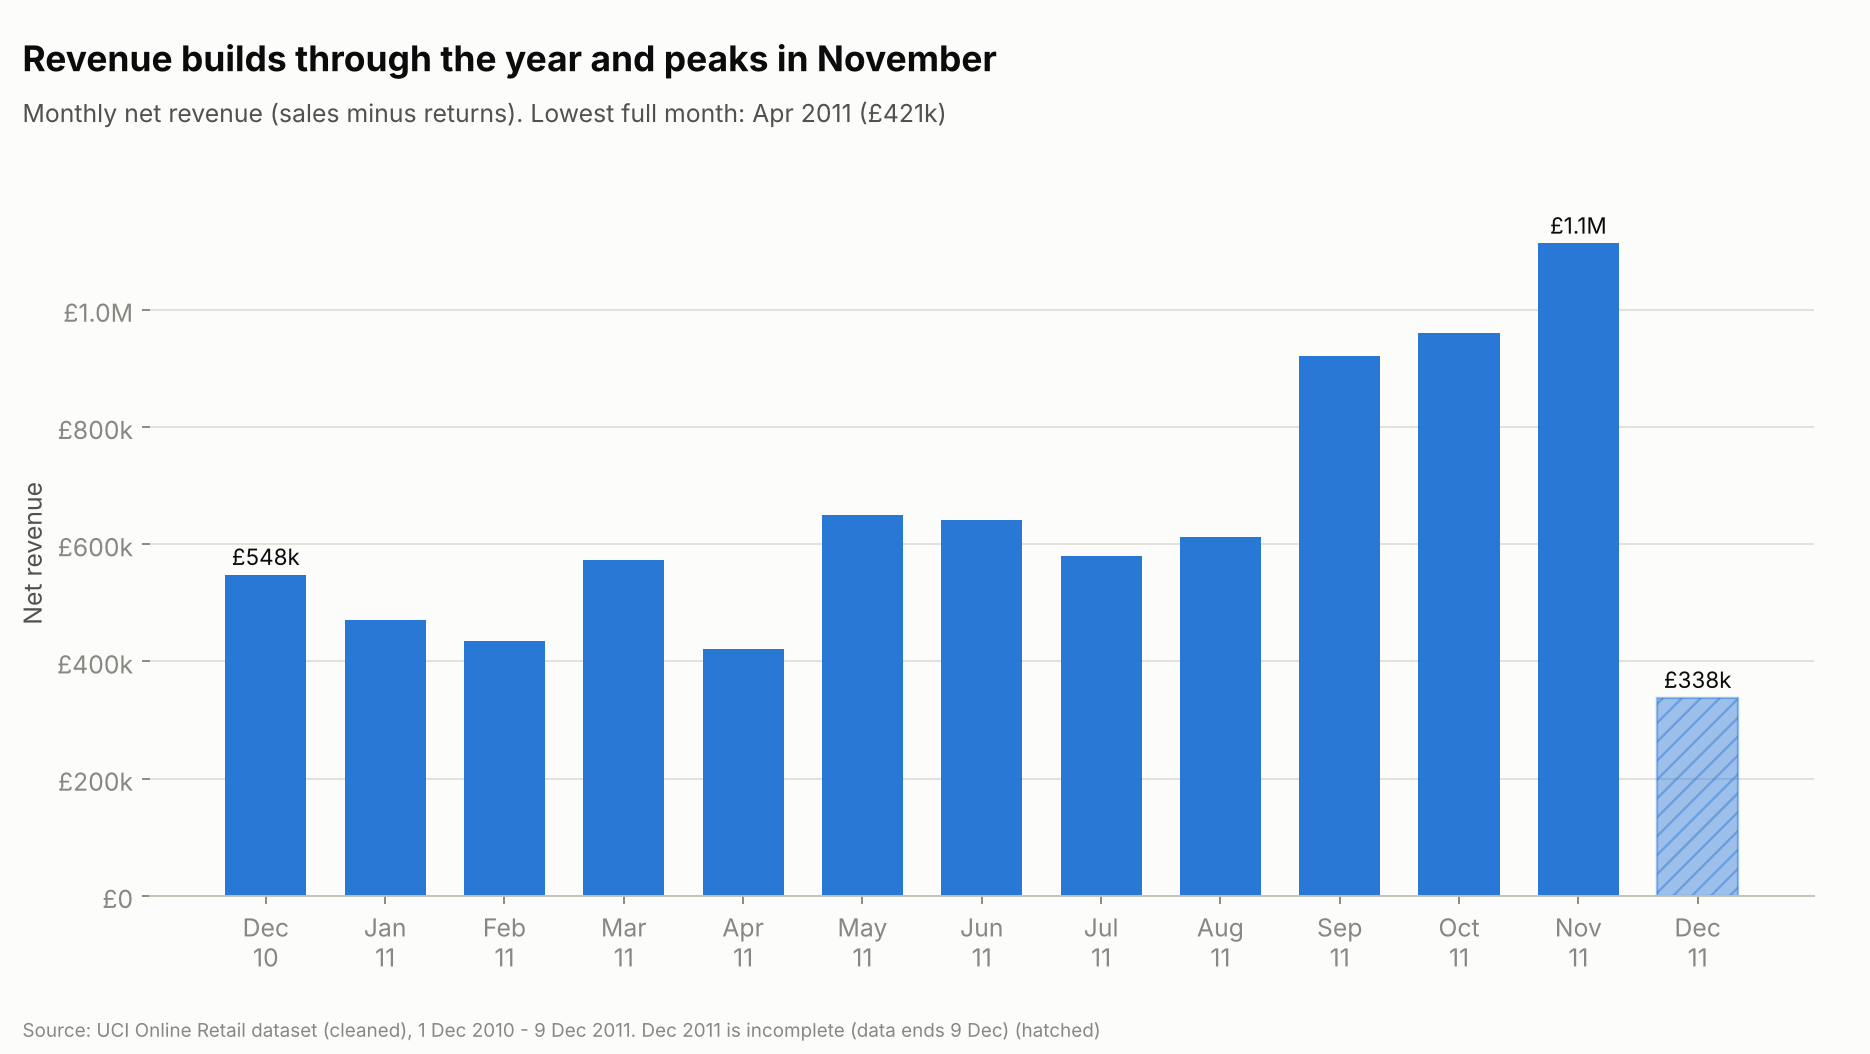

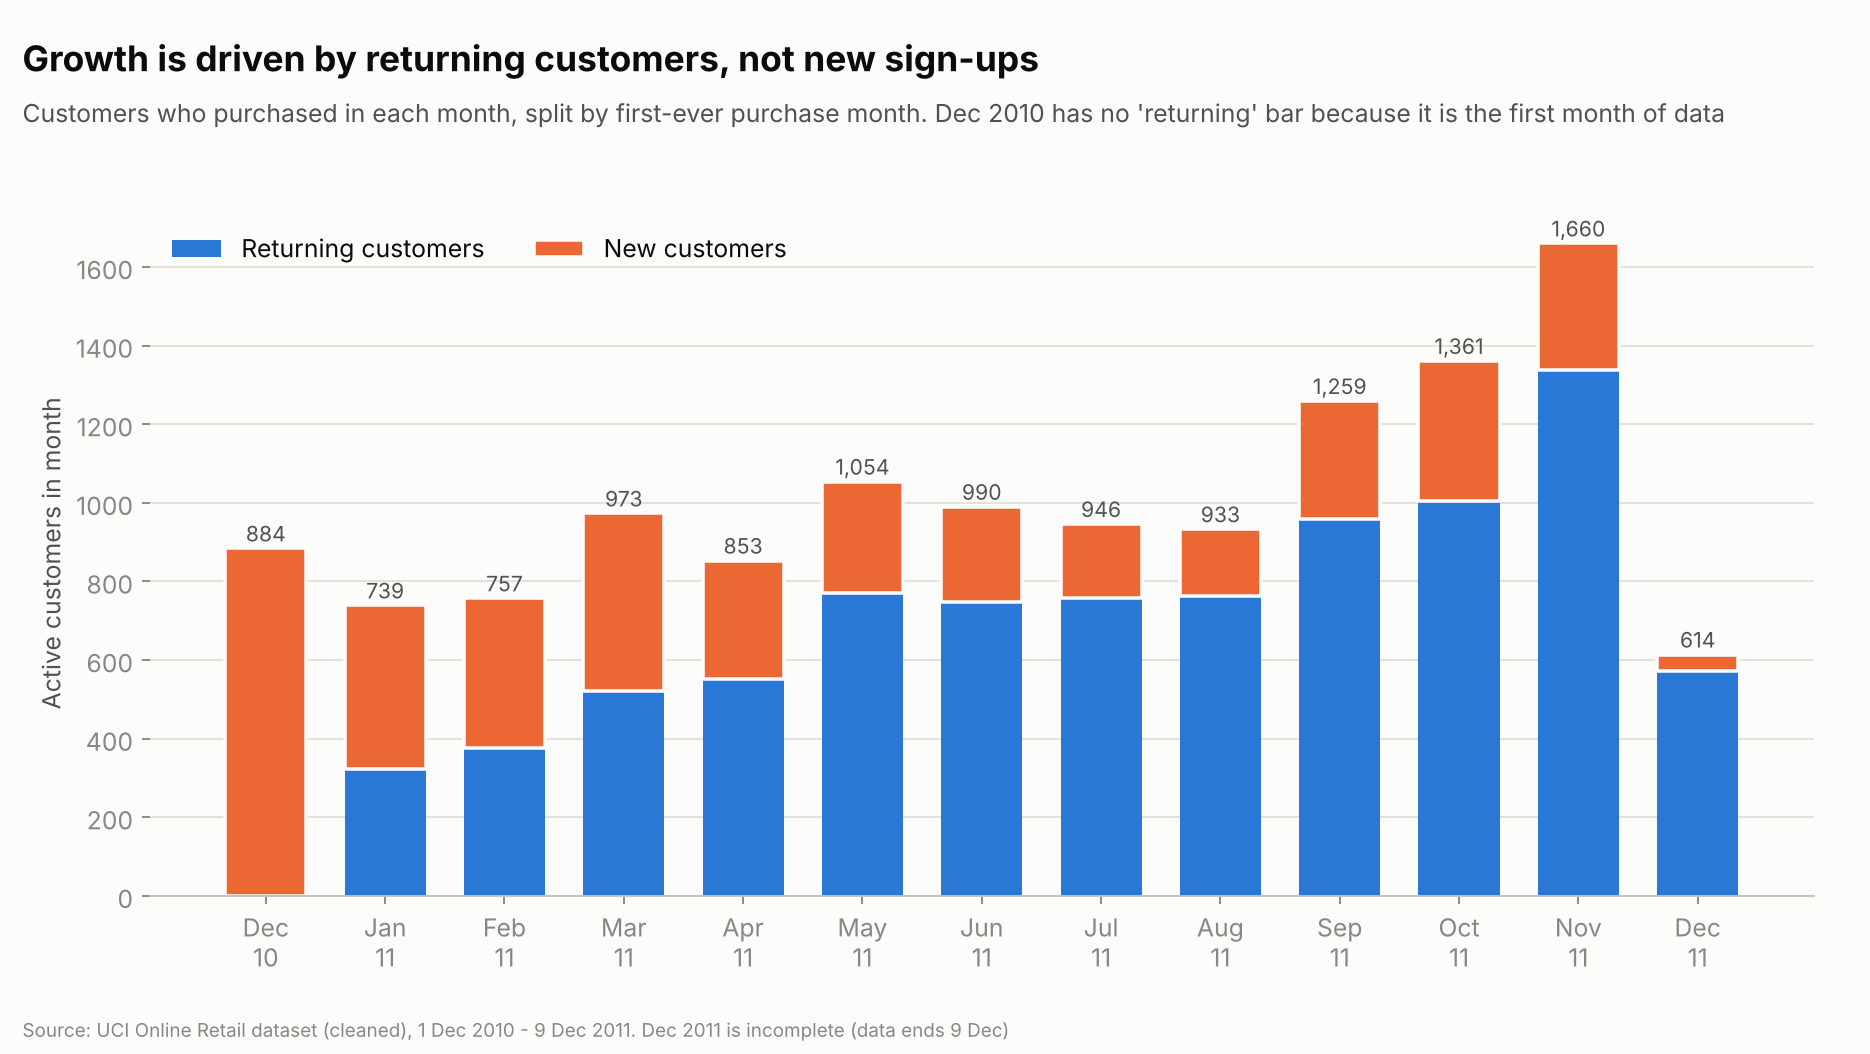

In [10]:
monthly = cm.monthly_trends(sales, returns)
display(monthly[["month", "orders", "active_customers", "new_customers", "returning_customers", "gross_revenue", "returns_value", "net_revenue", "avg_order_value", "is_partial"]])
viz.monthly_revenue(monthly, VIZ)
display(Image(filename=str(VIZ / "01_monthly_revenue_trend.png")))
viz.customers_new_vs_returning(monthly, VIZ)
display(Image(filename=str(VIZ / "02_new_vs_returning_customers.png")))

### 4.3 Purchasing patterns: weekday, hour, order size

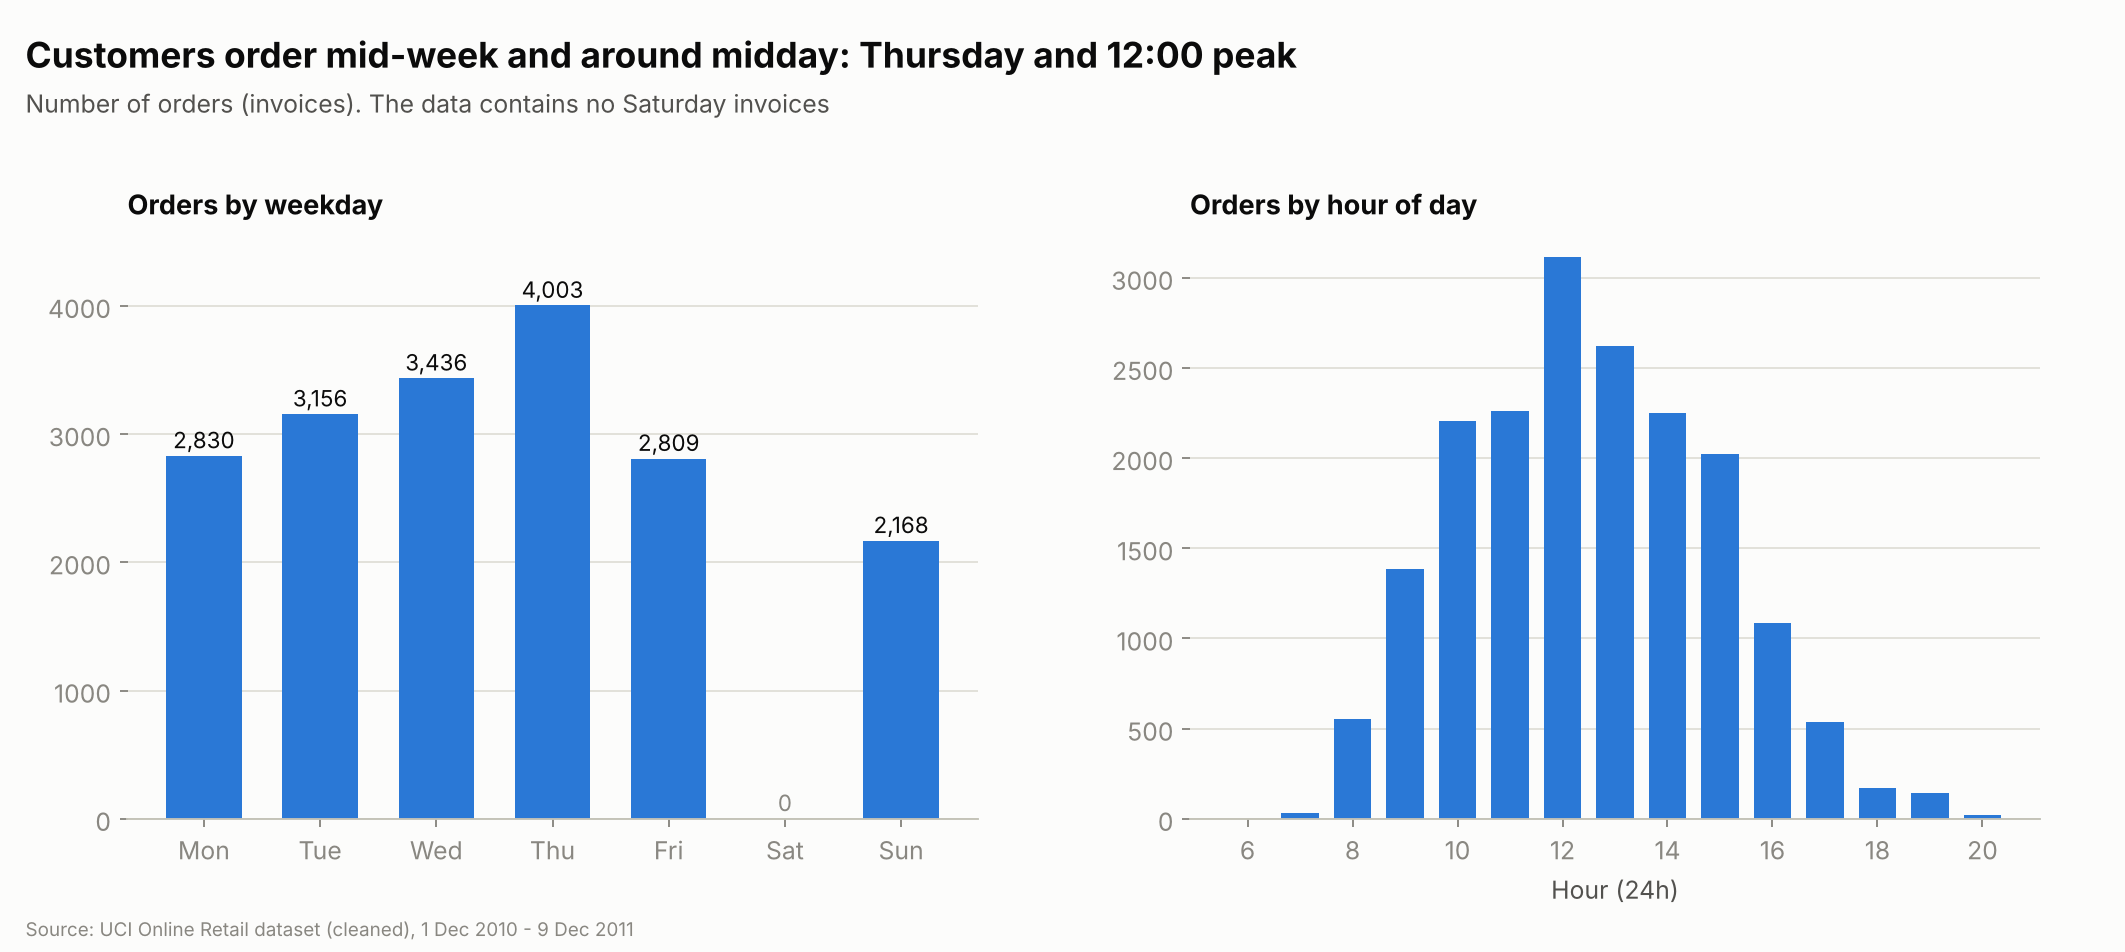

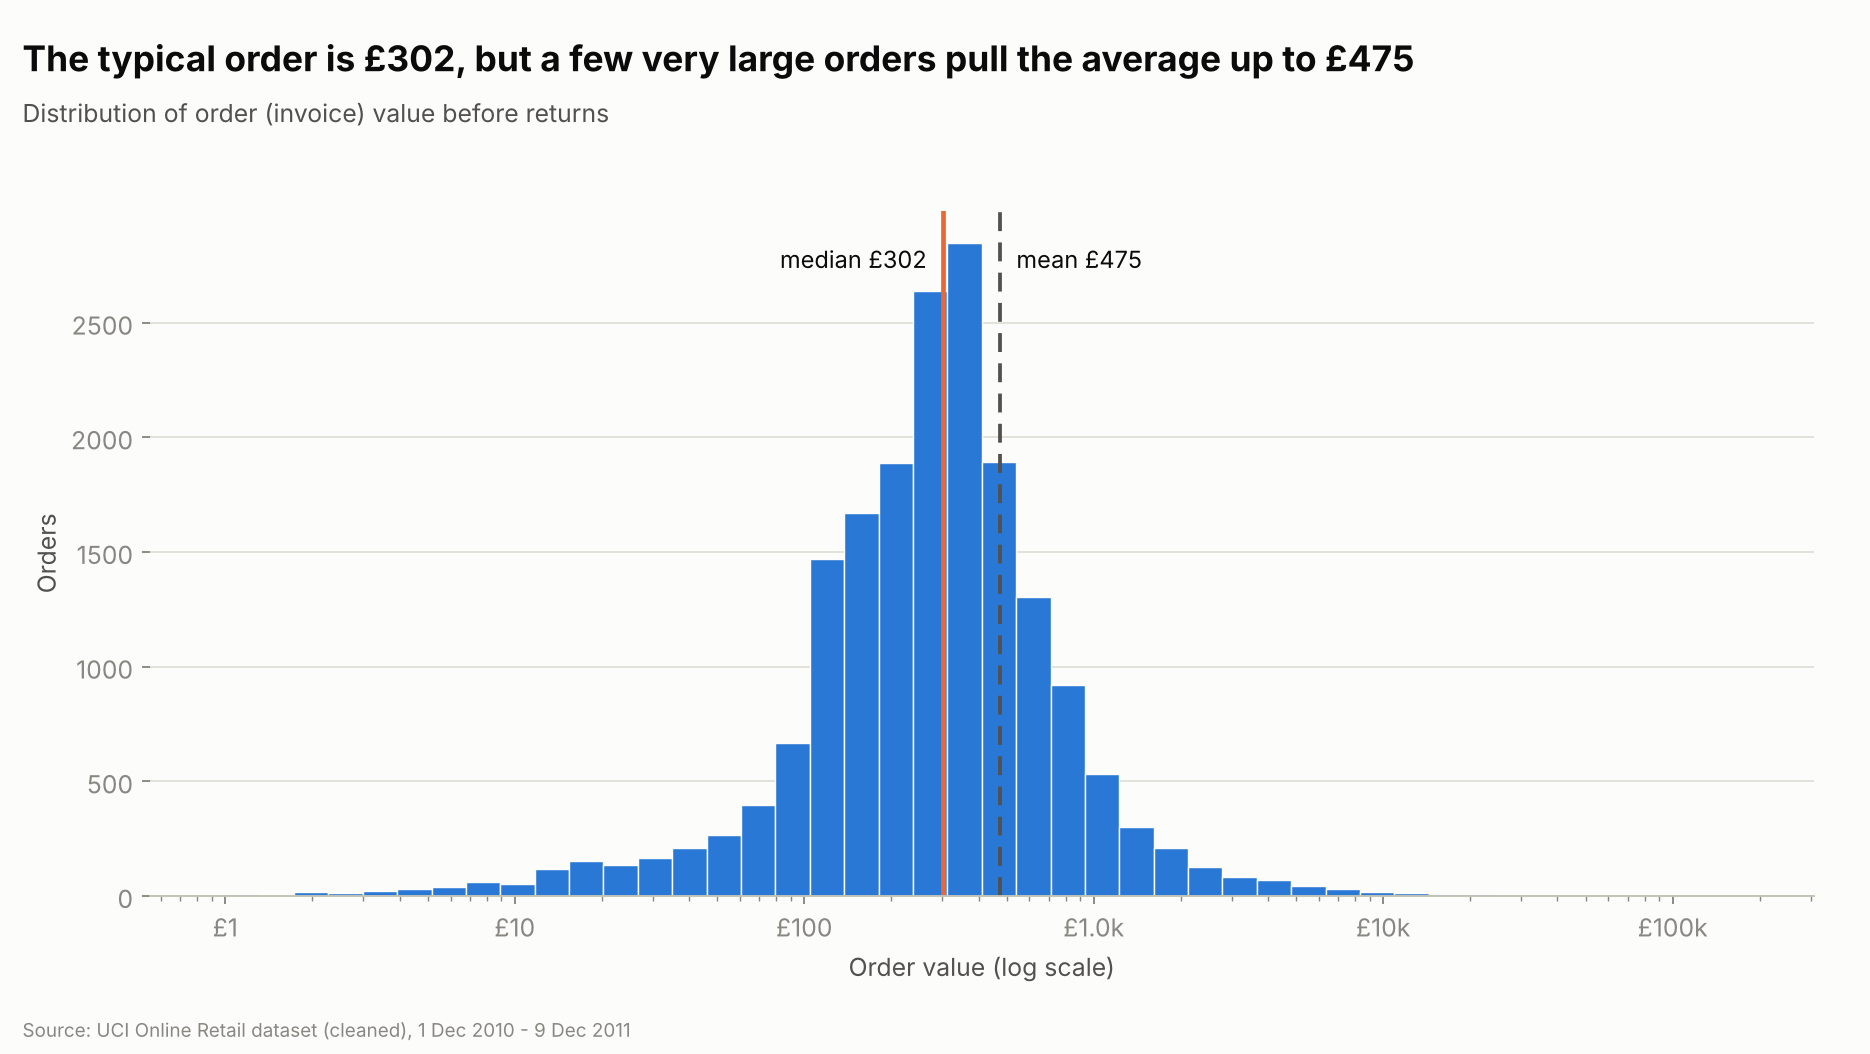

In [11]:
weekday, hour = cm.weekday_hour_patterns(sales)
viz.weekday_hour_chart(weekday, hour, VIZ)
display(Image(filename=str(VIZ / "14_weekday_hour_patterns.png")))
basket = cm.basket_stats(sales)
viz.order_value_chart(basket, VIZ)
display(Image(filename=str(VIZ / "17_order_value_distribution.png")))

### 4.4 Repeat vs one-time customers and purchase frequency

,type,customers,gross_revenue,net_revenue,avg_orders,avg_order_value,pct_customers,pct_net_revenue
0,One-time customers,1505,"626,605.90","536,274.98",1.00,416.35,34.73,6.49
1,Repeat customers,2829,"8,110,621.74","7,733,124.93",5.97,415.02,65.27,93.51


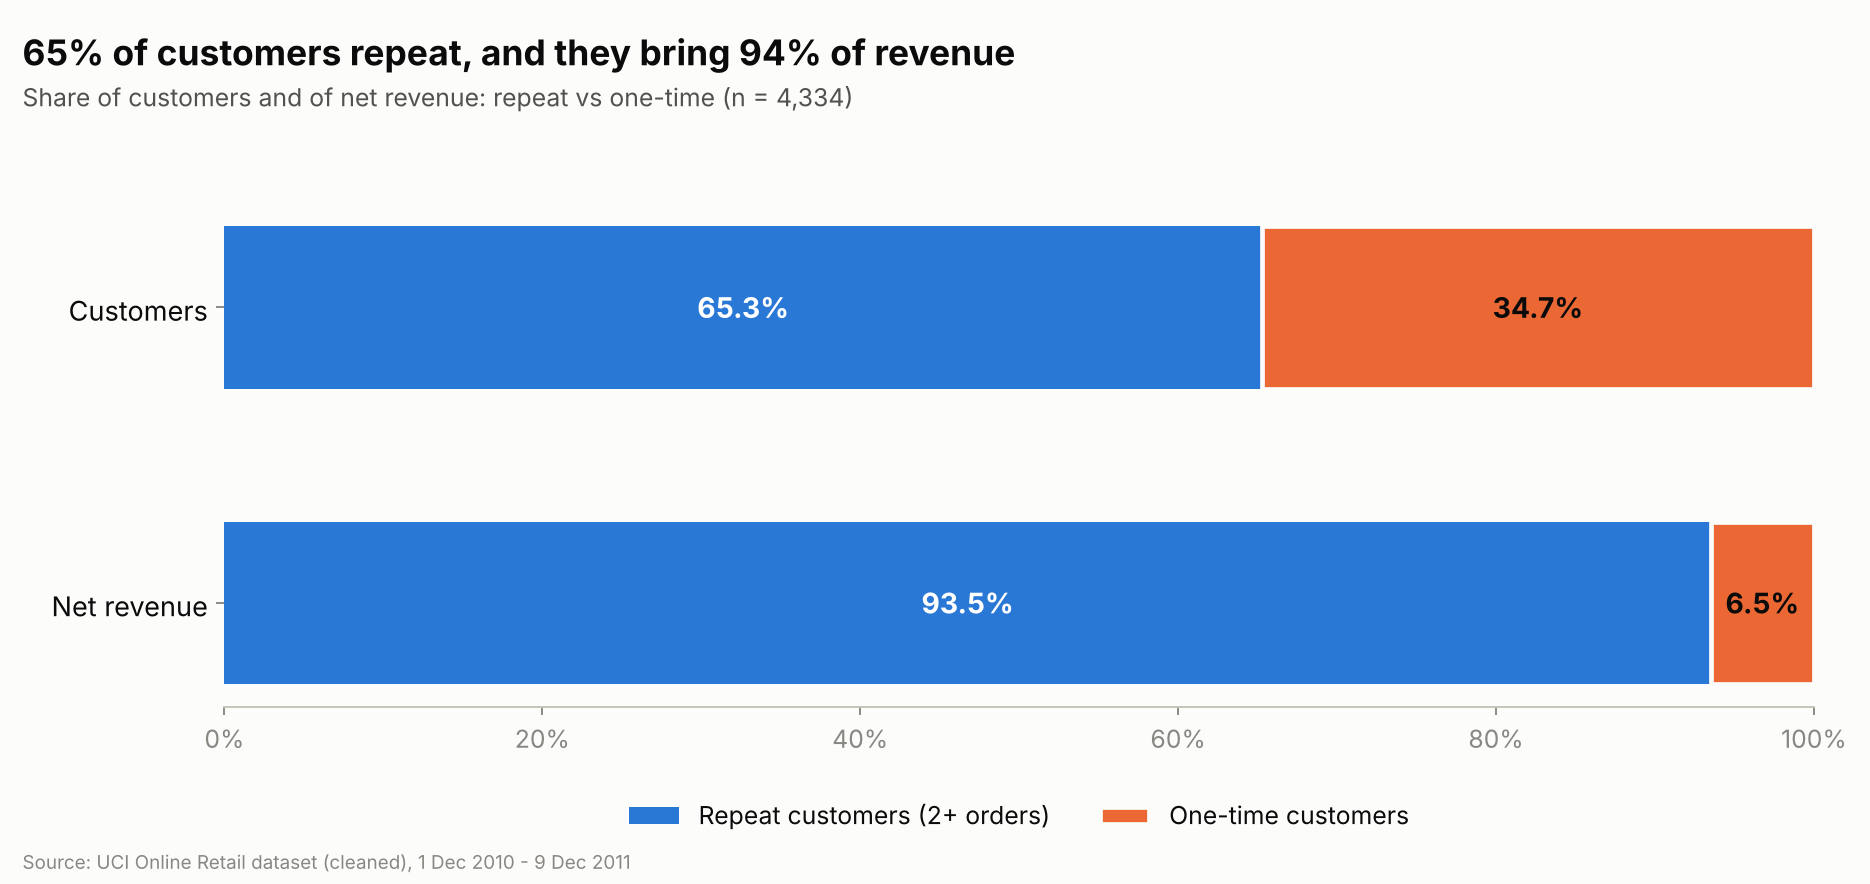

,orders,customers,net_revenue,pct_customers,pct_net_revenue
0,1,1505,"536,274.98",34.73,6.49
1,2,831,"540,081.46",19.17,6.53
2,3,502,"592,657.34",11.58,7.17
3,4,395,"559,589.63",9.11,6.77
4,5,236,"407,213.67",5.45,4.92
5,6-9,479,"1,289,712.58",11.05,15.60
6,10-19,279,"1,541,166.46",6.44,18.64
7,20+,107,"2,802,703.79",2.47,33.89


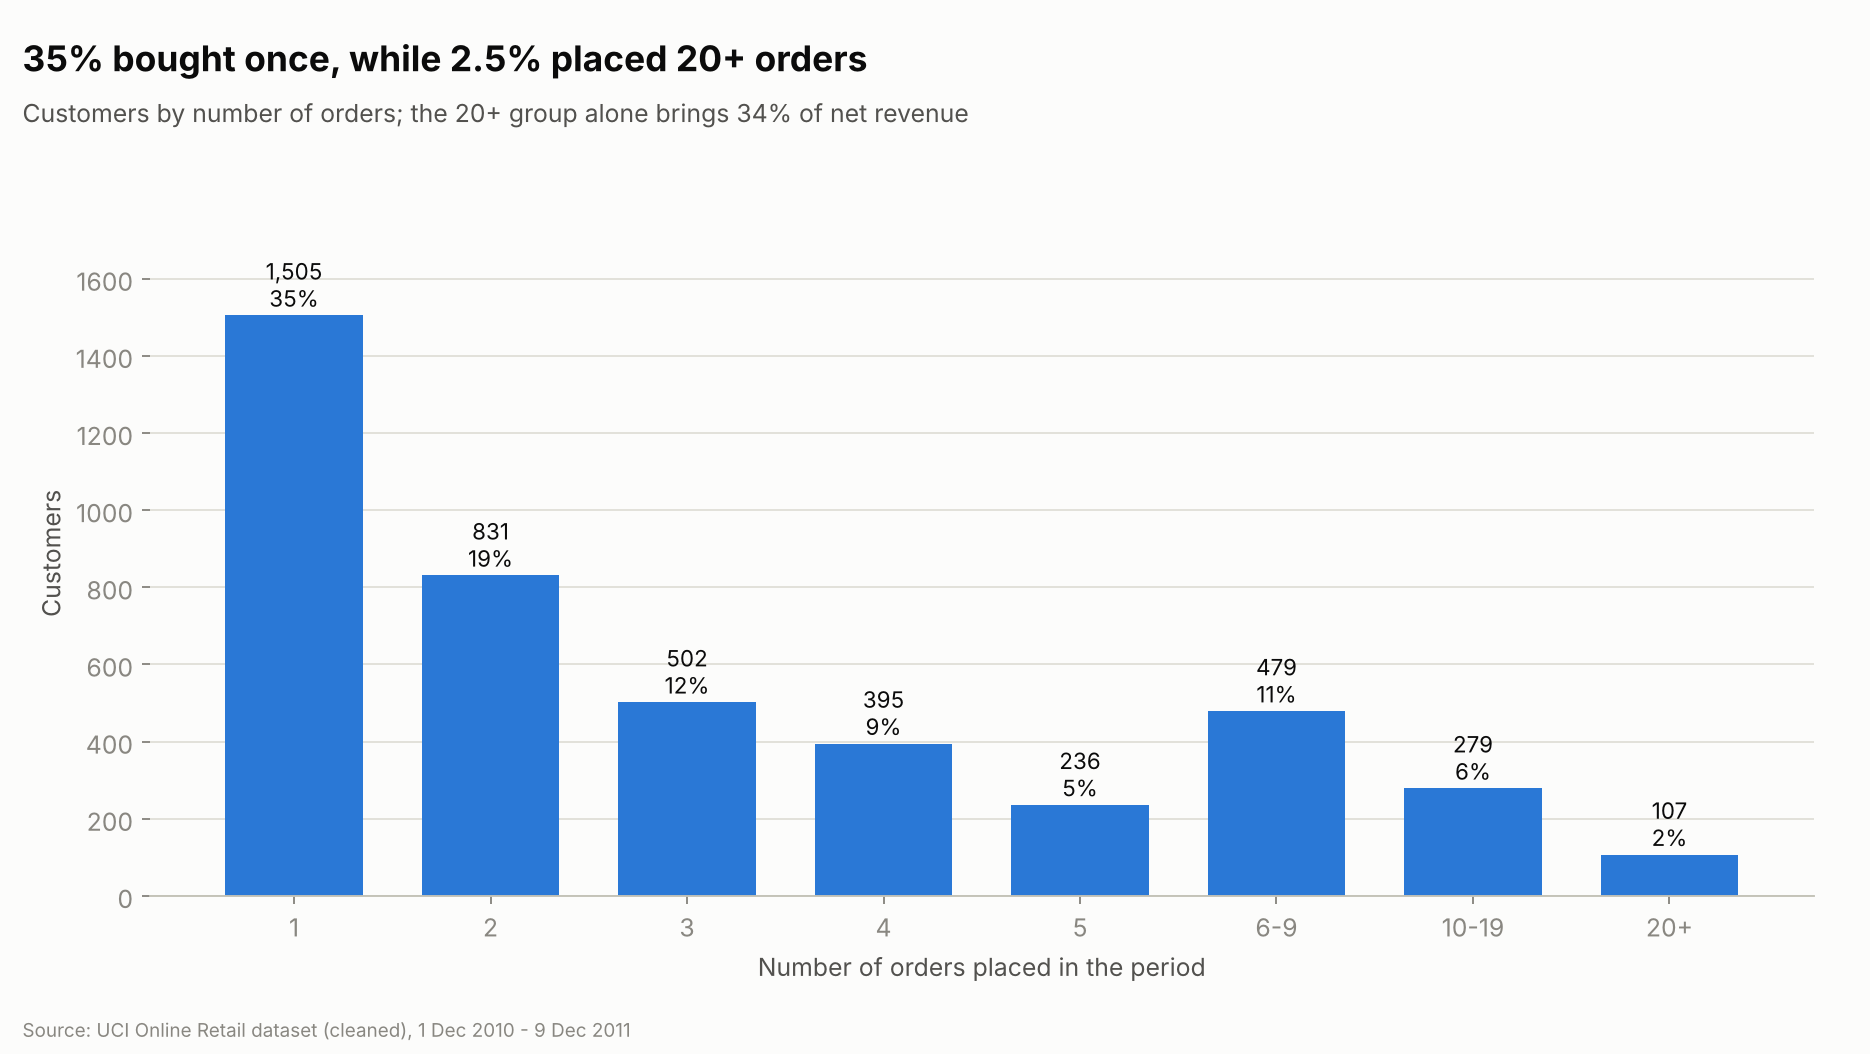

In [12]:
rv = cm.repeat_vs_onetime(cust)
display(rv)
viz.repeat_vs_onetime_chart(rv, VIZ)
display(Image(filename=str(VIZ / "09_repeat_vs_onetime.png")))
fd = cm.frequency_distribution(cust)
display(fd)
viz.purchase_frequency_chart(fd, VIZ)
display(Image(filename=str(VIZ / "10_purchase_frequency.png")))

Days between purchases: median 28, mean 46, 75th percentile 58
Second order within 60 days: {'window_days': 60, 'eligible_customers': 3728, 'repeat_within_window': 1390, 'rate_pct': 37.29}
Second order within 90 days: {'window_days': 90, 'eligible_customers': 3368, 'repeat_within_window': 1593, 'rate_pct': 47.3}


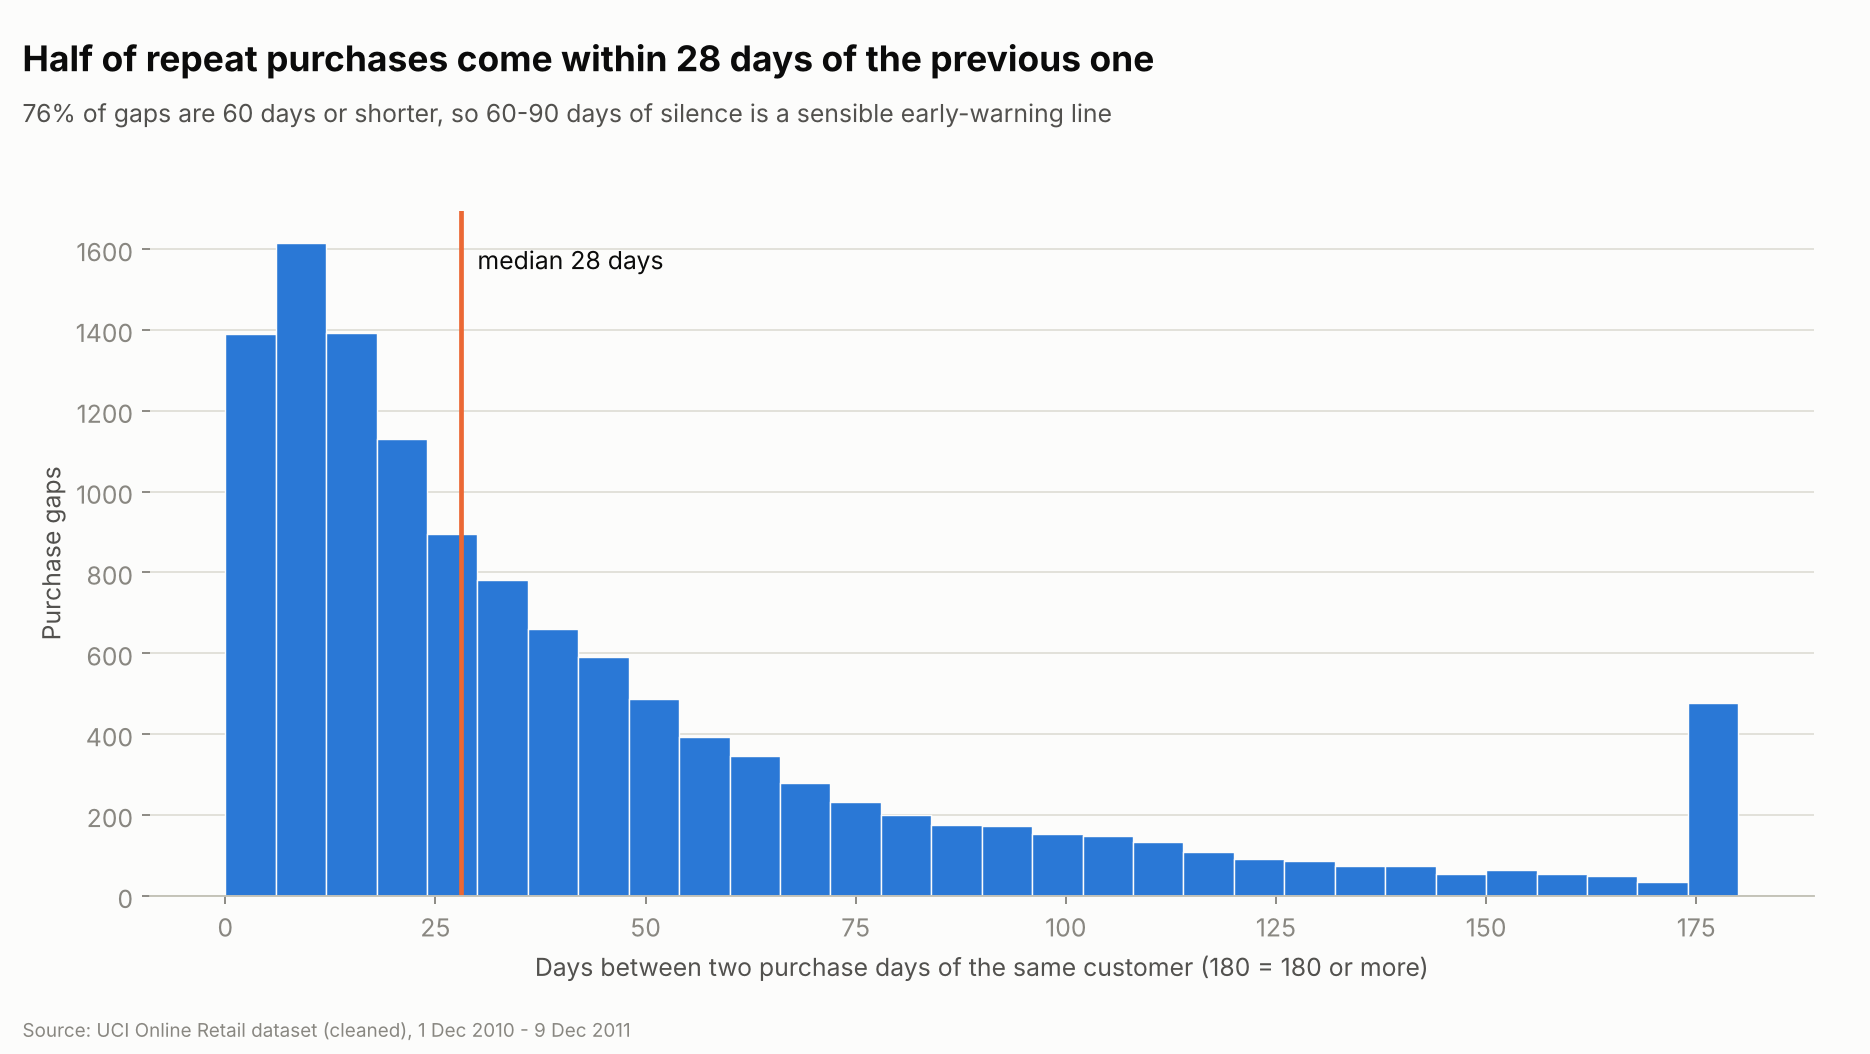

In [13]:
gaps = cm.purchase_gaps(sales)
print(f"Days between purchases: median {gaps.median():.0f}, mean {gaps.mean():.0f}, 75th percentile {gaps.quantile(.75):.0f}")
repeat90 = cm.repeat_within_days(sales, 90)
repeat60 = cm.repeat_within_days(sales, 60)
print("Second order within 60 days:", repeat60)
print("Second order within 90 days:", repeat90)
viz.purchase_gap_chart(gaps, VIZ)
display(Image(filename=str(VIZ / "11_days_between_purchases.png")))

### 4.5 Revenue concentration (Pareto)

,value
customers_in_base,"4,320.00"
top_1pct_share,30.15
top_5pct_share,48.80
top_10pct_share,60.12
top_20pct_share,73.75
bottom_50pct_share,8.12
gini,0.71
customers_for_80pct_revenue,"1,166.00"
customers_for_80pct_revenue_pct,26.99
top_customer_share,3.37


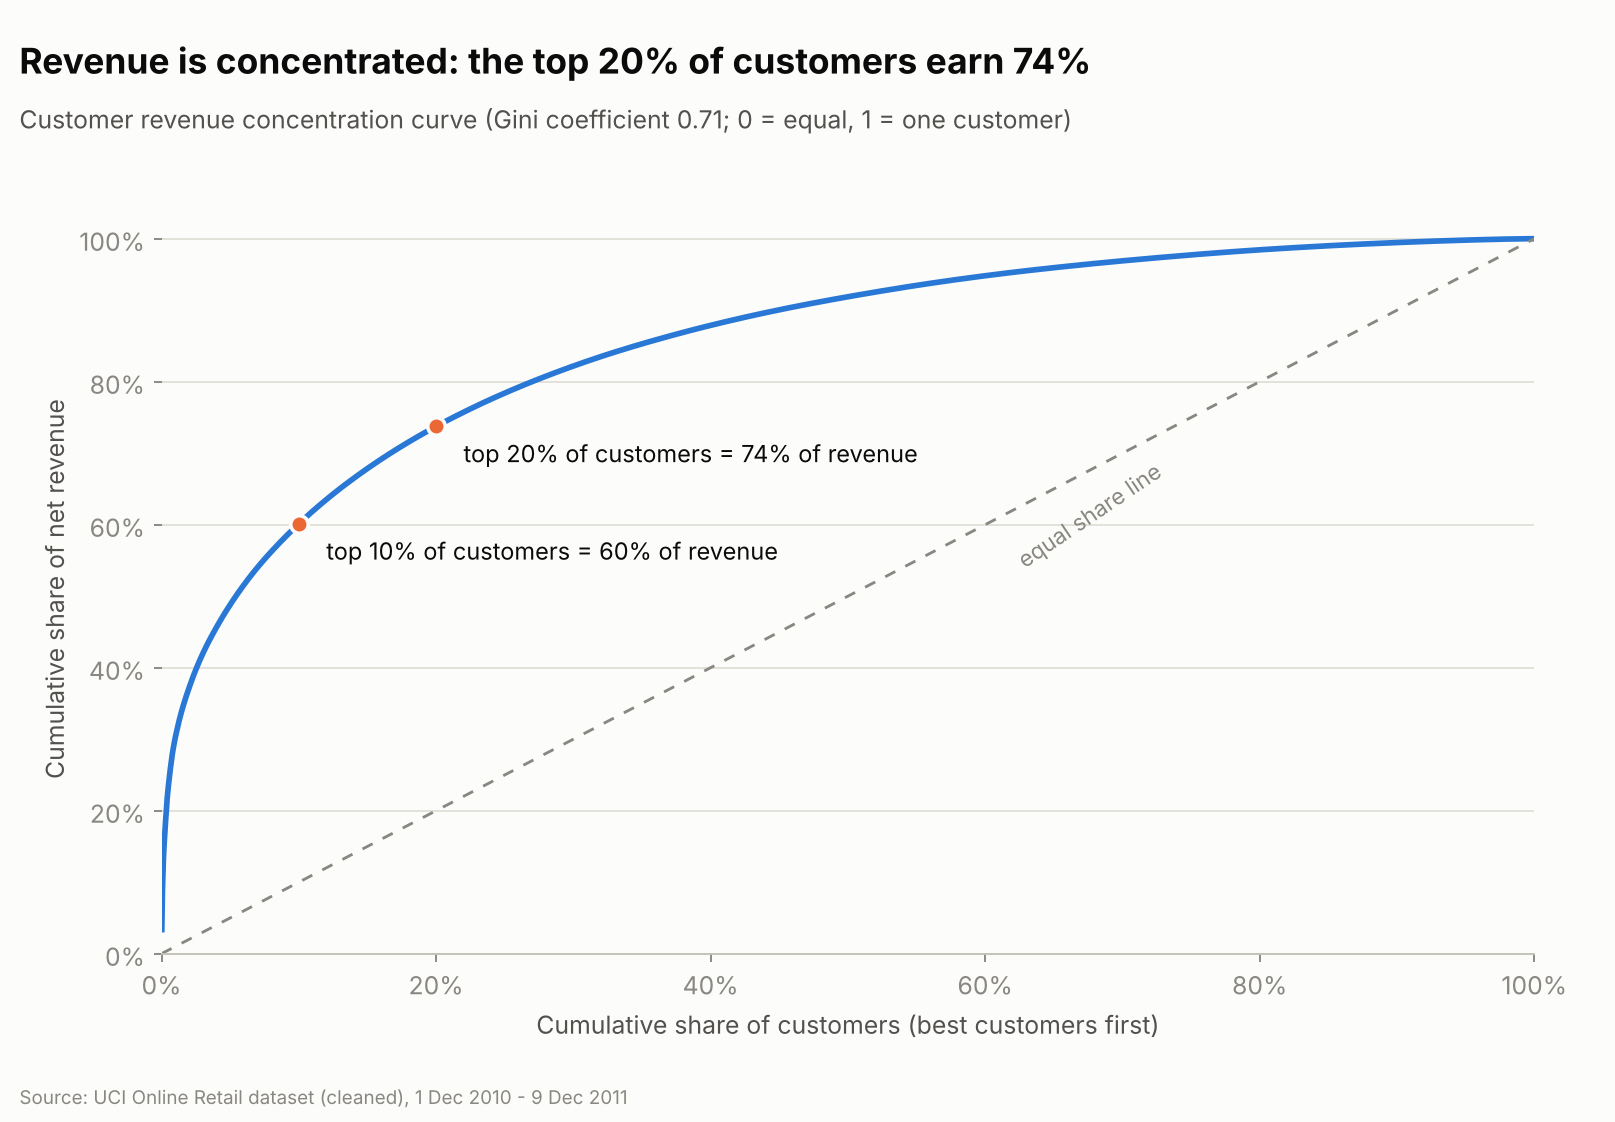

In [14]:
curve, conc = cm.revenue_concentration(cust)
display(pd.Series(conc, name="value").to_frame())
viz.pareto_chart(curve, conc, VIZ)
display(Image(filename=str(VIZ / "12_revenue_concentration.png")))

### 4.6 Retention: monthly cohorts

k,0,1,2,3,4,5,6,7,8,9,10,11
cohort,,,,,,,,,,,,
2010-12,100.00,36.50,32.40,38.30,36.20,39.80,36.20,34.80,35.30,39.50,37.30,50.20
2011-01,100.00,21.90,26.70,22.80,31.70,28.80,24.80,24.00,29.60,32.70,36.50,NaN
2011-02,100.00,18.70,18.70,28.70,27.10,24.50,25.50,27.40,24.70,30.50,NaN,NaN
2011-03,100.00,14.80,25.20,19.90,22.30,16.80,26.80,23.00,27.90,NaN,NaN,NaN
2011-04,100.00,21.00,20.30,21.00,19.70,22.70,21.70,26.00,NaN,NaN,NaN,NaN
2011-05,100.00,19.00,17.30,17.30,20.80,23.20,26.40,NaN,NaN,NaN,NaN,NaN
2011-06,100.00,17.40,15.70,26.40,23.10,33.10,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,100.00,17.60,20.30,22.50,27.30,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,100.00,20.10,24.30,24.30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Average share of a monthly cohort active in a later month (Jan-Nov 2011 cohorts): 23.8%


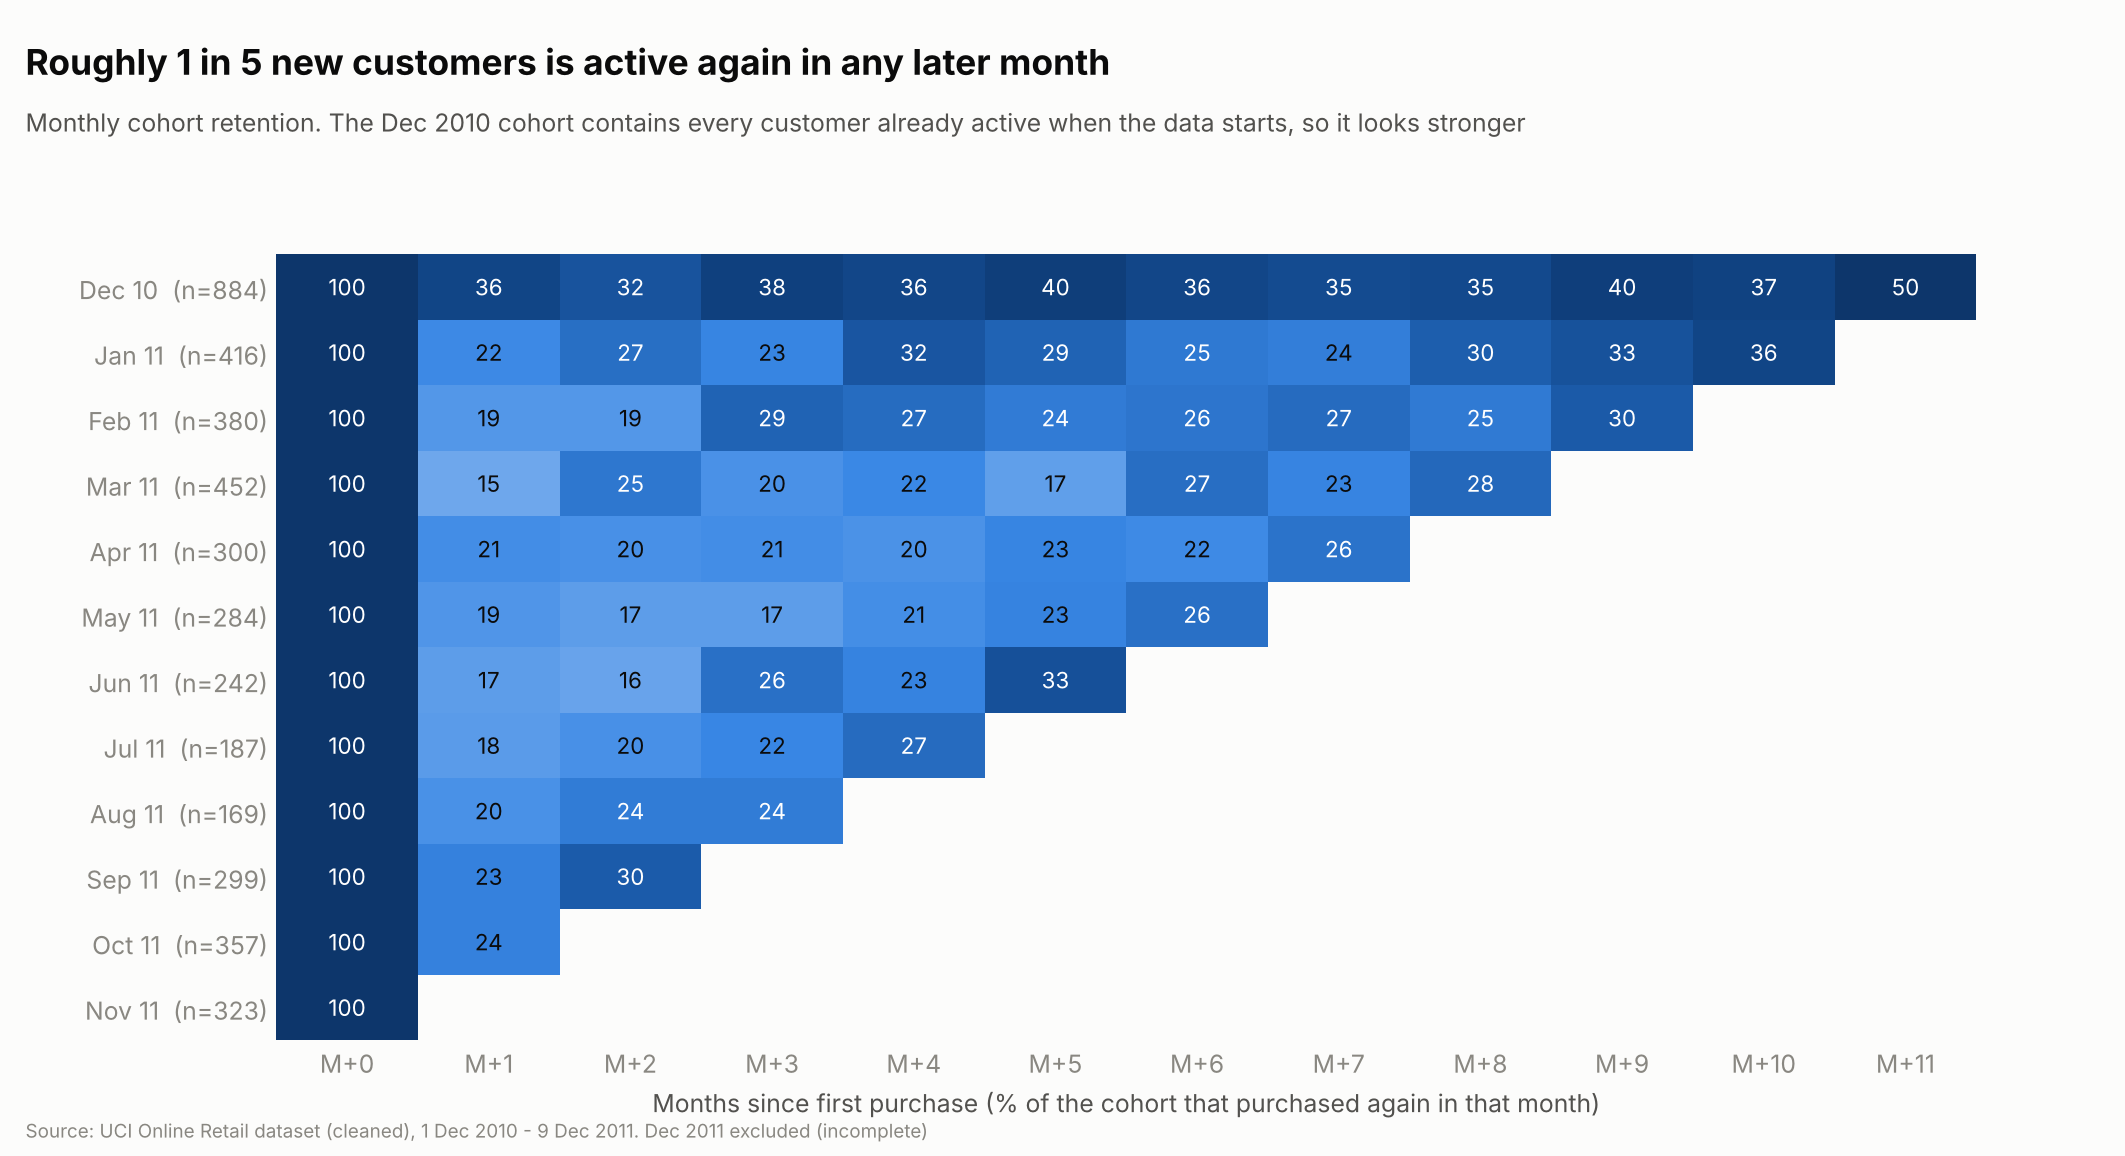

In [15]:
ret, cohort_sizes = cm.cohort_retention(sales)
display(ret)
later = ret.drop(index=ret.index[0]).drop(columns=0)  # leave out the Dec-2010 'already active' cohort and month 0
cohort_avg = float(np.nanmean(later.values))
print(f"Average share of a monthly cohort active in a later month (Jan-Nov 2011 cohorts): {cohort_avg:.1f}%")
viz.cohort_heatmap(ret, cohort_sizes, VIZ)
display(Image(filename=str(VIZ / "13_cohort_retention.png")))

### 4.7 Products and countries
Product ranking uses **net** revenue, so a product whose big order was cancelled does not look like a best seller. The data has no product categories, so analysis is by product.

,StockCode,description,net_revenue,net_units,customers,return_rate_pct
0,22423,REGENCY CAKESTAND 3 TIER,"132,567.70","11,519.00",881,6.82
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,"93,923.15","34,185.00",856,6.59
2,85099B,JUMBO BAG RED RETROSPOT,"83,056.52","44,963.00",635,2.33
3,47566,PARTY BUNTING,"67,628.43","15,011.00",708,1.68
4,84879,ASSORTED COLOUR BIRD ORNAMENT,"56,331.91","35,215.00",678,0.14
5,23084,RABBIT NIGHT LIGHT,"51,042.84","27,045.00",450,0.41
6,22502,PICNIC BASKET WICKER SMALL,"46,963.10","1,410.00",175,0.81
7,79321,CHILLI LIGHTS,"45,915.41","9,566.00",205,0.76
8,22086,PAPER CHAIN KIT 50'S CHRISTMAS,"41,423.78","15,138.00",613,2.72
9,21137,BLACK RECORD COVER FRAME,"38,990.63","11,386.00",140,0.14


,country,customers,net_revenue,avg_orders,pct_customers,pct_net_revenue,revenue_per_customer
0,United Kingdom,3916,"6,806,233.62",4.23,90.36,82.31,"1,738.06"
1,Netherlands,9,"283,479.54",10.33,0.21,3.43,"31,497.73"
2,EIRE,3,"246,732.47",85.33,0.07,2.98,"82,244.16"
3,Germany,94,"200,627.16",4.71,2.17,2.43,"2,134.33"
4,France,87,"181,385.54",4.36,2.01,2.19,"2,084.89"
5,Australia,9,"138,087.64",6.56,0.21,1.67,"15,343.07"
6,Spain,29,"53,078.25",3.03,0.67,0.64,"1,830.28"
7,Switzerland,19,"50,160.61",2.21,0.44,0.61,"2,640.03"


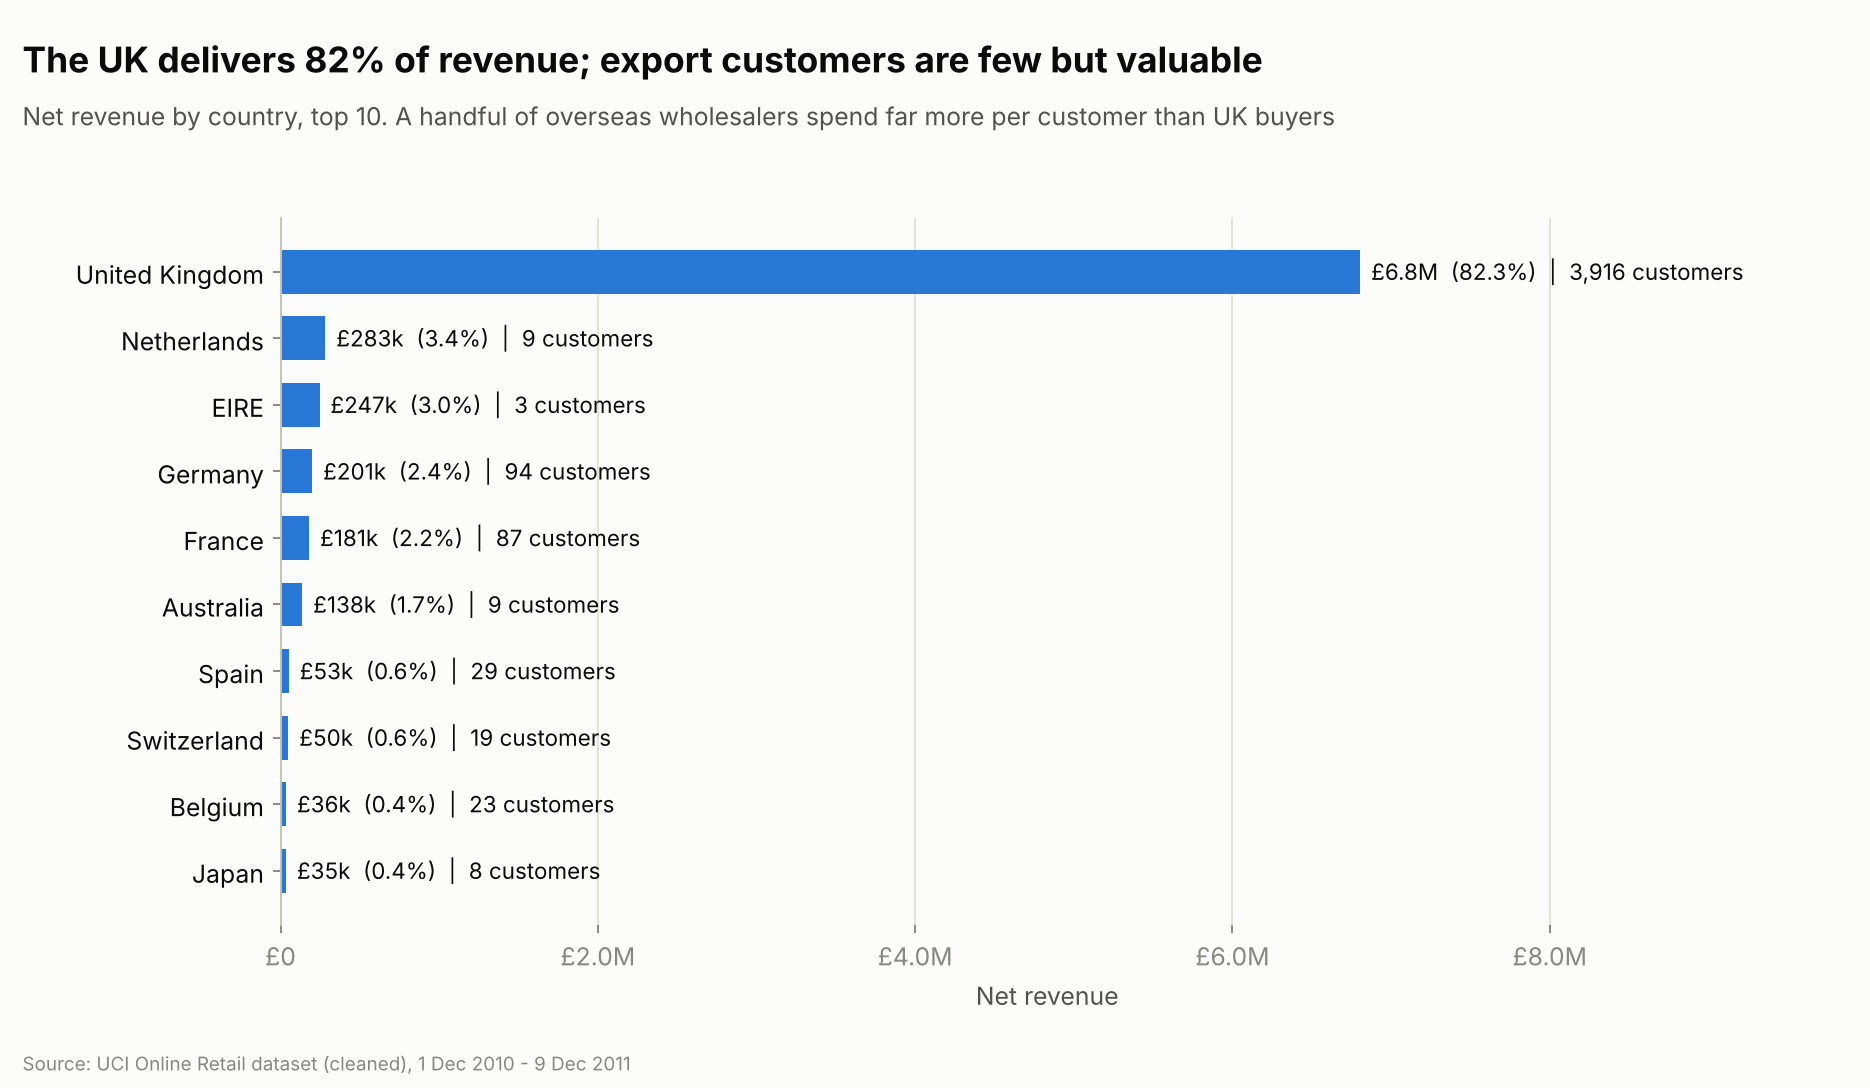

In [16]:
products = cm.product_summary(sales, returns)
display(products.head(10)[["StockCode", "description", "net_revenue", "net_units", "customers", "return_rate_pct"]])
country = cm.country_summary(cust)
display(country.head(8))
viz.country_chart(country, VIZ)
display(Image(filename=str(VIZ / "15_revenue_by_country.png")))

## 5. RFM segmentation
### 5.1 Method
* **Recency** = days since last purchase (lower is better) | **Frequency** = number of orders | **Monetary** = net spend (sales - returns)
* Each is scored **1-5** using the 20th/40th/60th/80th percentiles of the customer base as cut-points.
* *Why not equal-size bins?* About a third of customers bought exactly once; any rank-based split would have to separate identical customers at random. Percentile cut-points give identical customers identical scores.
* Customers whose returns cancelled all their spend (net <= 0) are not scored - they have no value to rank. They are listed below.
* Segments come from the transparent rule table below (no black-box clustering), so a marketer can read and change them.

In [17]:
pop, no_value = ra.rfm_population(cust)
print(f"Customers scored: {len(pop):,} | not scored (net spend <= 0): {len(no_value)}")
display(no_value[["CustomerID", "country", "frequency", "gross_revenue", "return_value", "net_revenue"]])
scored, cuts = ra.score_rfm(pop)
display(cuts)
display(pd.DataFrame({"segment": list(ra.SEGMENT_RULES), "rule": list(ra.SEGMENT_RULES.values())}))

Customers scored: 4,320 | not scored (net spend <= 0): 14


,CustomerID,country,frequency,gross_revenue,return_value,net_revenue
0,12346,United Kingdom,1,"77,183.60","77,183.60",0.00
89,12454,Spain,1,"3,528.34","3,528.34",0.00
168,12558,USA,1,269.96,269.96,0.00
210,12607,USA,1,"1,579.51","1,579.51",0.00
767,13364,United Kingdom,1,134.96,134.96,0.00
983,13672,United Kingdom,2,186.39,186.39,0.00
1050,13762,United Kingdom,1,306.72,306.72,0.00
1629,14557,United Kingdom,1,788.38,788.38,0.00
1793,14792,United Kingdom,1,6.20,6.20,0.00
3076,16546,United Kingdom,2,787.15,883.08,-95.93


,metric,p20,p40,p60,p80
0,recency_days,14.60,33.00,72.00,180.00
1,frequency,1.00,2.00,3.00,6.00
2,net_revenue,242.42,471.50,909.32,"1,998.86"


,segment,rule
0,Champions,R >= 4 and F >= 4: bought very recently and buy often
1,Loyal Customers,"R >= 3 and F >= 3 (not Champions): regular buyers, reasonably recent"
2,New Customers,R >= 4 and F = 1: first purchase very recently
3,Potential Loyalists,"R >= 3 and F <= 2 (not New): recent, but only 1-2 purchases so far"
4,Can't Lose Them,R <= 2 and F >= 4 and M >= 4: our best spenders/frequent buyers who have gone quiet
5,At Risk,"R <= 2 and F >= 3 (not Can't Lose Them): used to buy repeatedly, now quiet"
6,Hibernating,R <= 2 and F <= 2: long inactive with little purchase history


In [18]:
seg = ra.assign_segments(scored)
seg["recommended_action"] = seg["segment"].astype(str).map(ra.SEGMENT_ACTIONS)
summary = ra.segment_summary(seg)
display(summary)

,segment,customers,net_revenue,avg_recency_days,avg_frequency,avg_net_revenue,median_net_revenue,avg_order_value,avg_return_rate_pct,pct_customers,pct_revenue,revenue_per_customer_index
0,Champions,1023,"5,536,893.13",13.13,10.67,"5,412.41","2,362.84",418.90,2.07,23.68,66.95,2.83
1,Loyal Customers,591,"1,052,658.23",39.13,4.47,"1,781.15","1,158.27",386.92,1.88,13.68,12.73,0.93
2,Potential Loyalists,754,"415,491.09",39.44,1.61,551.05,397.78,467.91,1.20,17.45,5.02,0.29
3,New Customers,236,"74,826.17",19.40,1.00,317.06,227.24,318.65,0.55,5.46,0.90,0.17
4,At Risk,242,"273,226.75",144.09,3.45,"1,129.04",681.16,398.25,2.86,5.60,3.30,0.59
5,Can't Lose Them,142,"330,265.36",122.29,5.88,"2,325.81","1,809.34",423.00,1.73,3.29,3.99,1.21
6,Hibernating,1332,"586,276.59",209.44,1.28,440.15,304.92,356.19,1.81,30.83,7.09,0.23


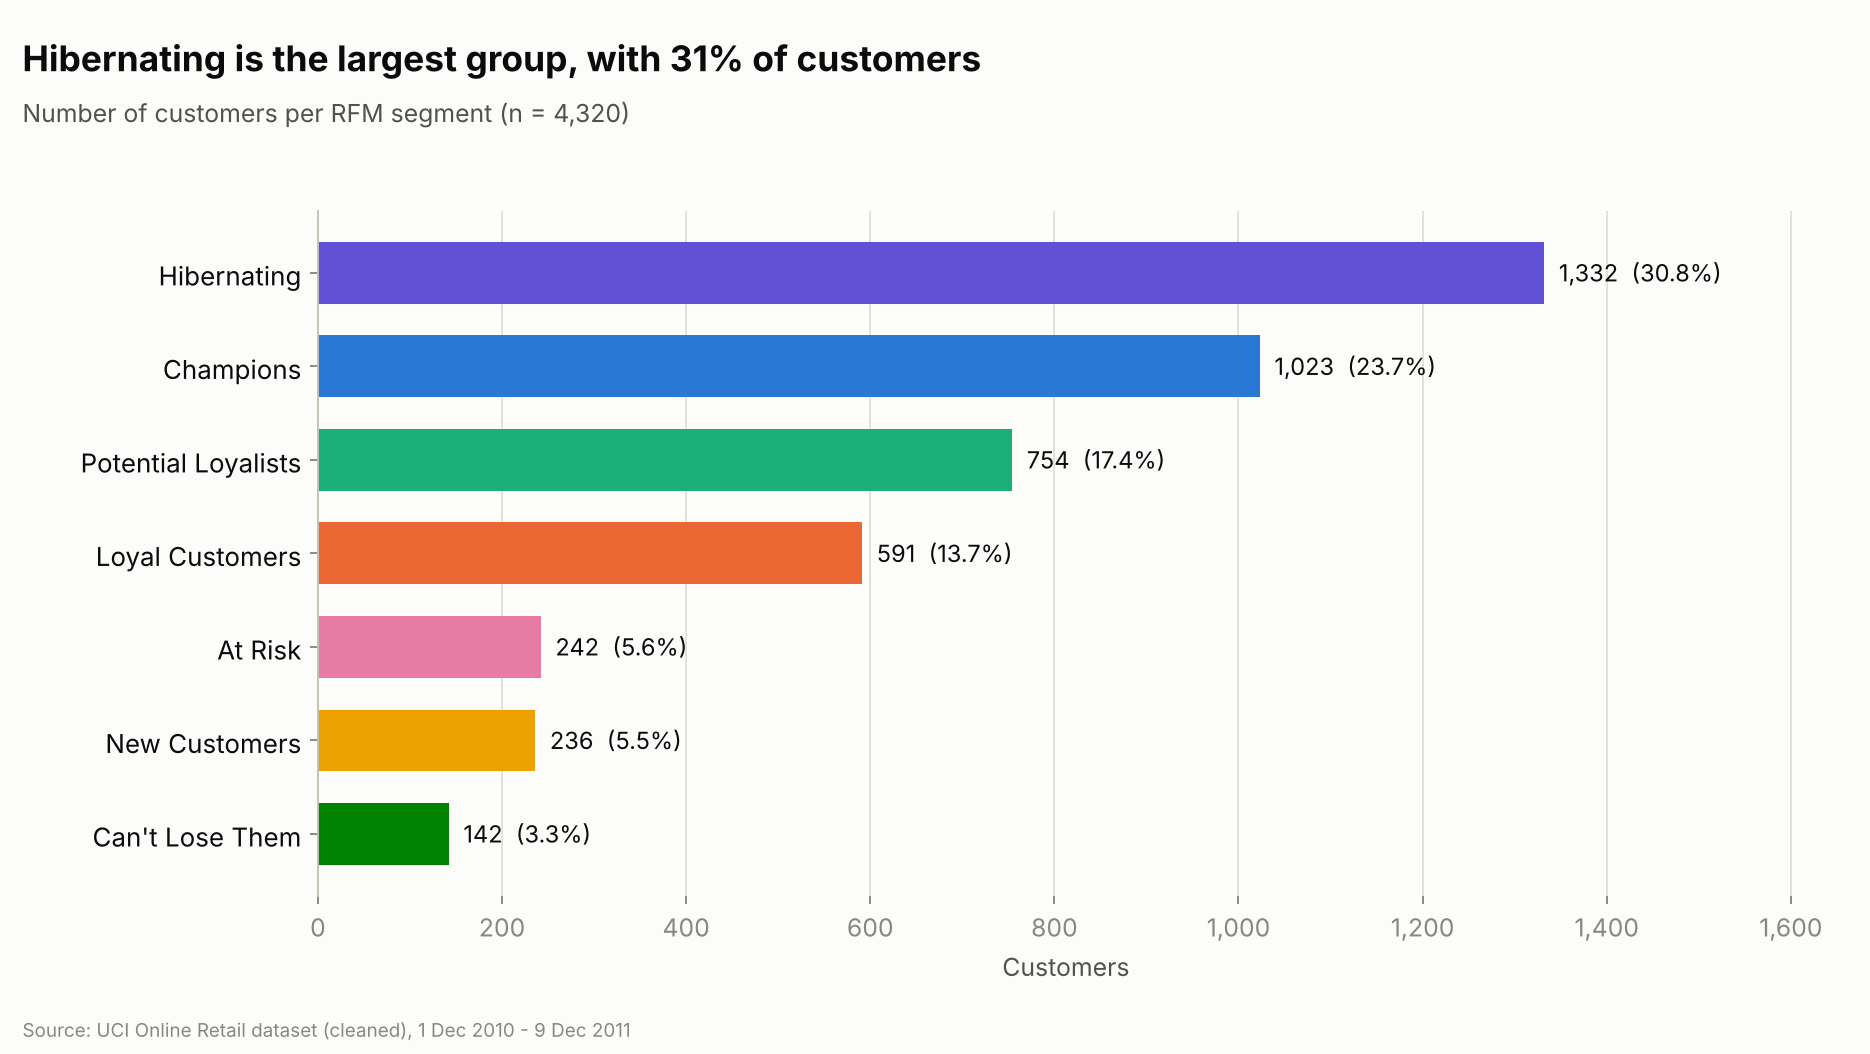

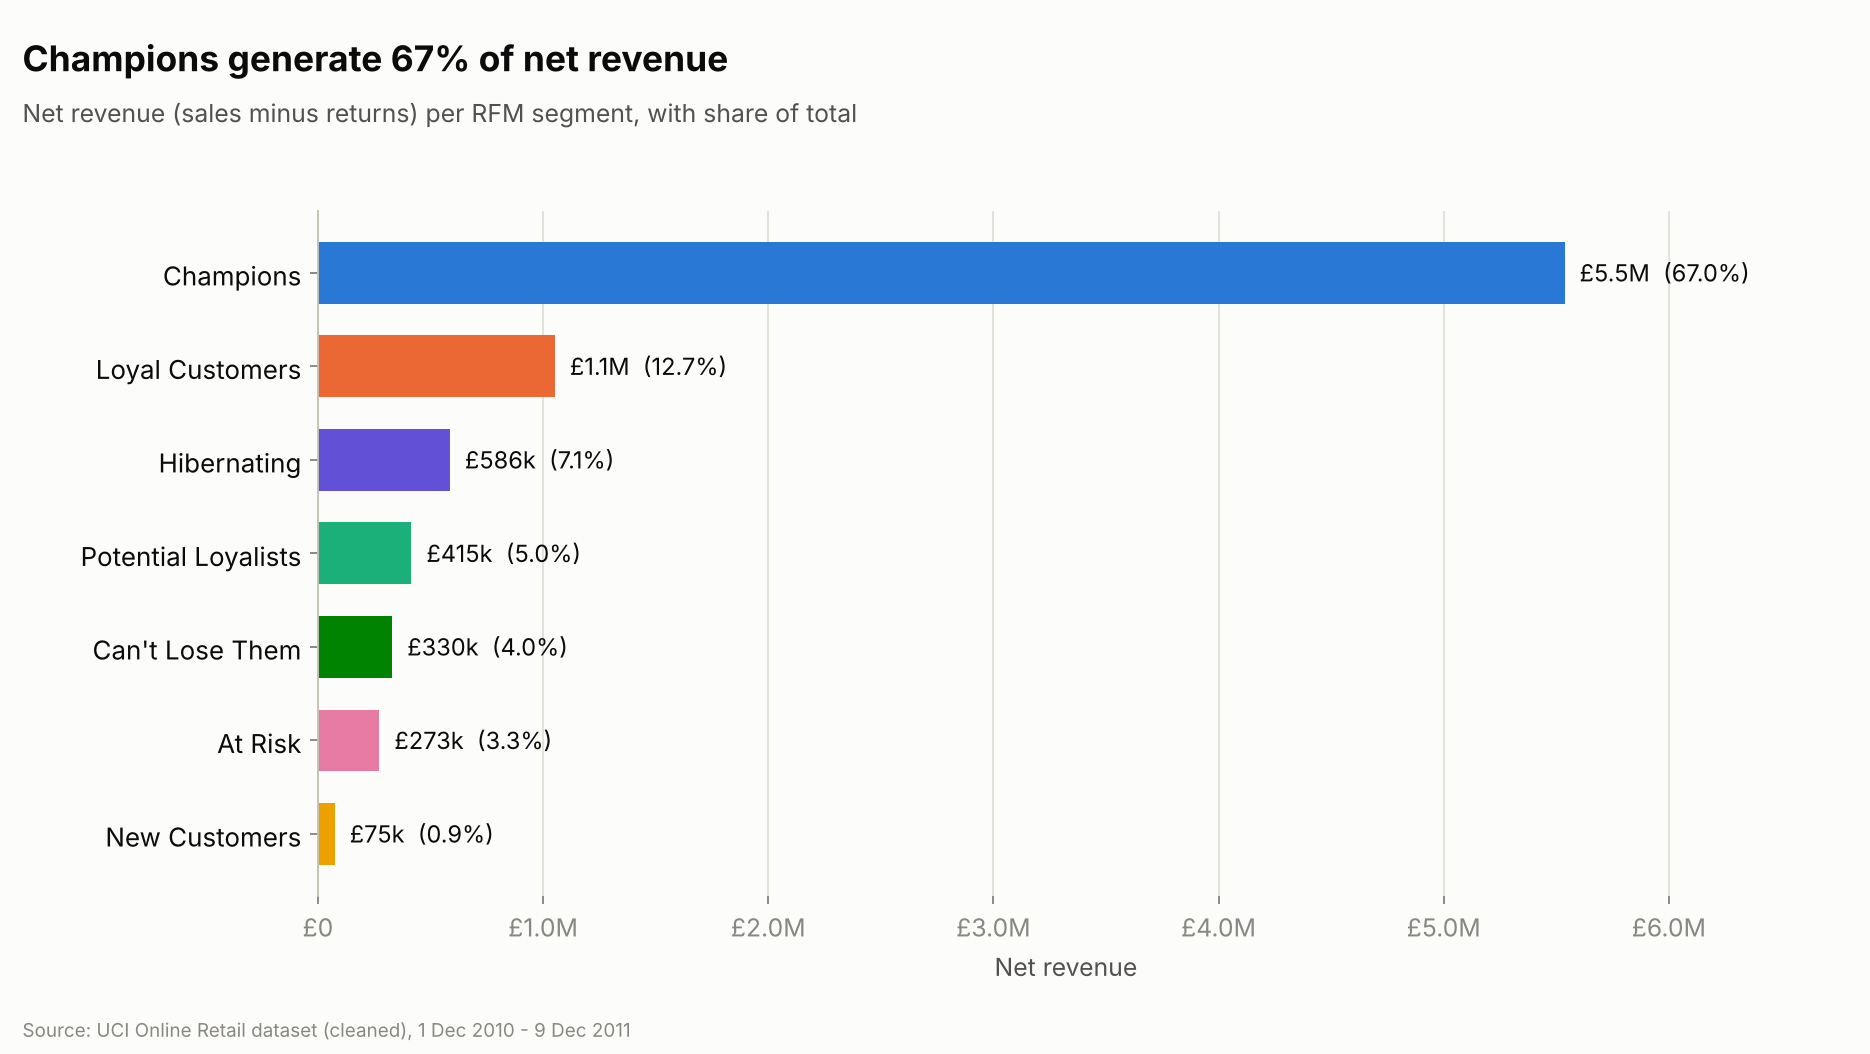

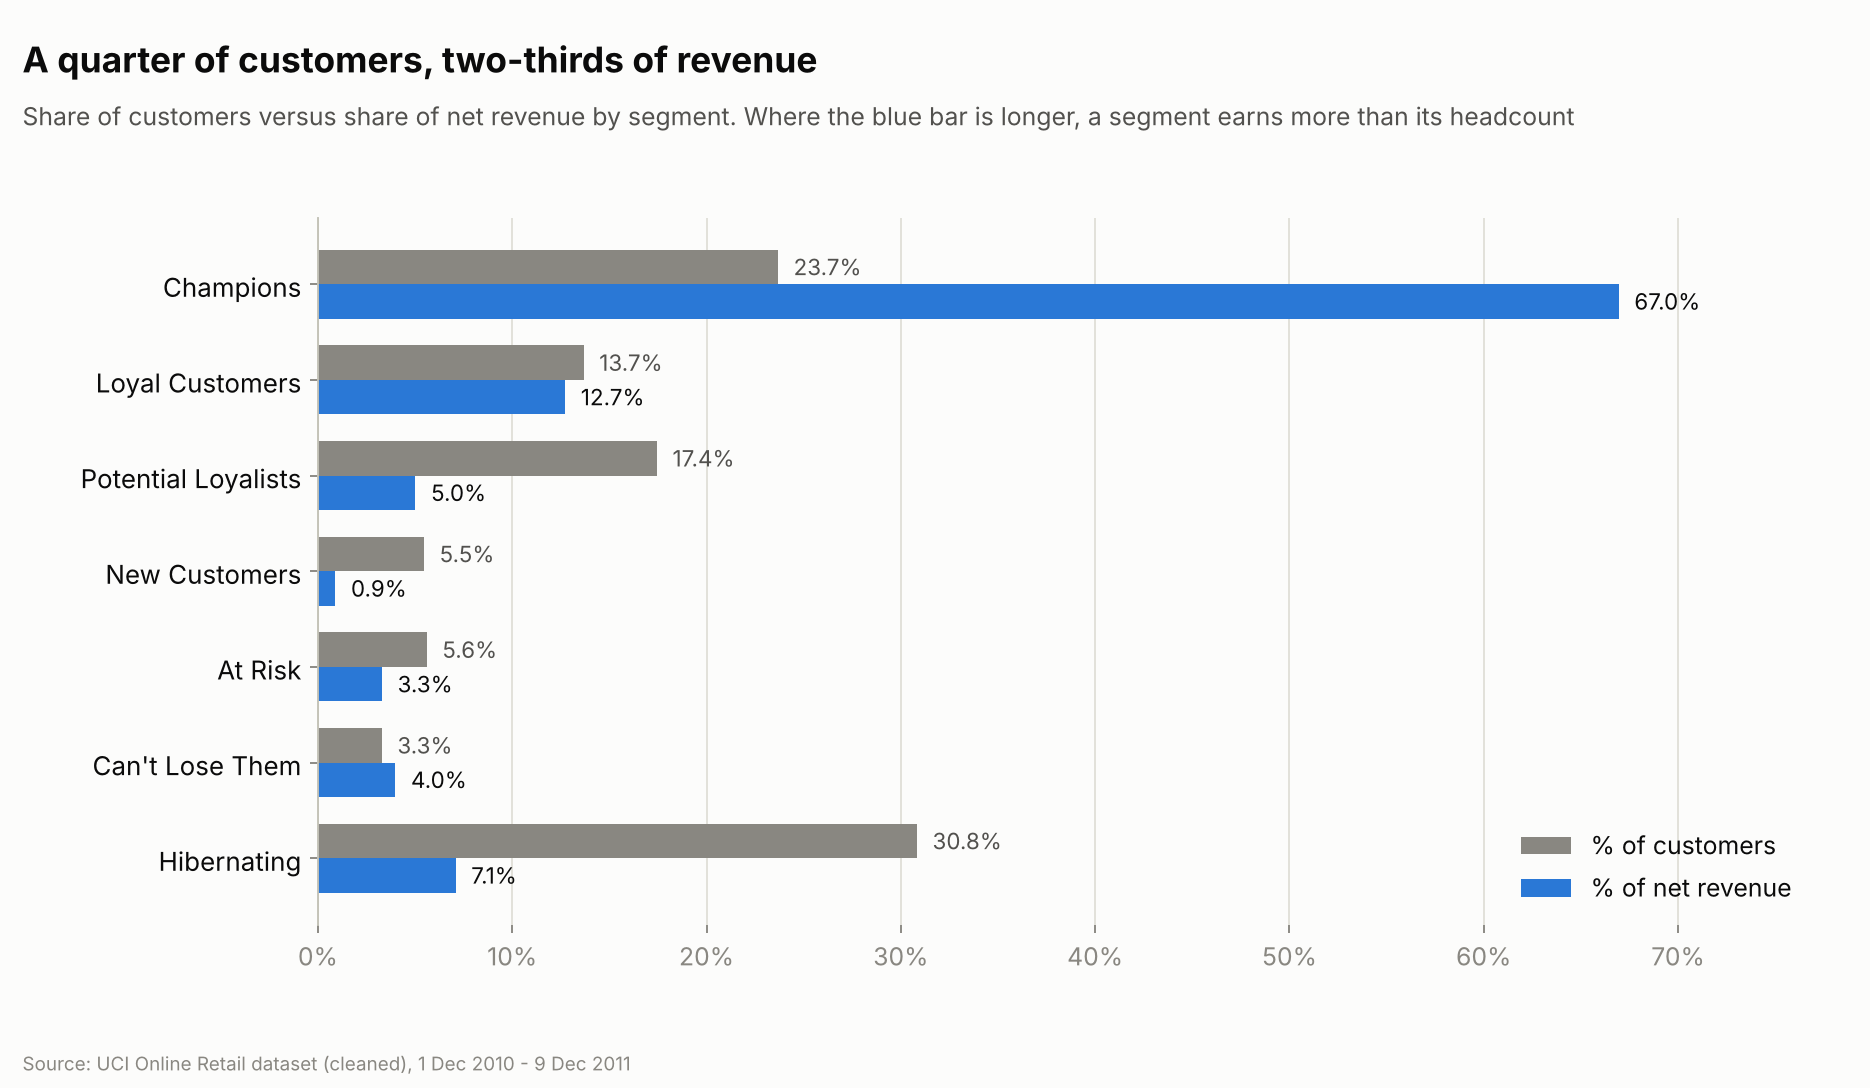

In [19]:
viz.segment_distribution(summary, VIZ)
display(Image(filename=str(VIZ / "03_segment_distribution.png")))
viz.revenue_by_segment(summary, VIZ)
display(Image(filename=str(VIZ / "04_revenue_by_segment.png")))
viz.customers_vs_revenue_share(summary, VIZ)
display(Image(filename=str(VIZ / "05_customer_vs_revenue_share.png")))

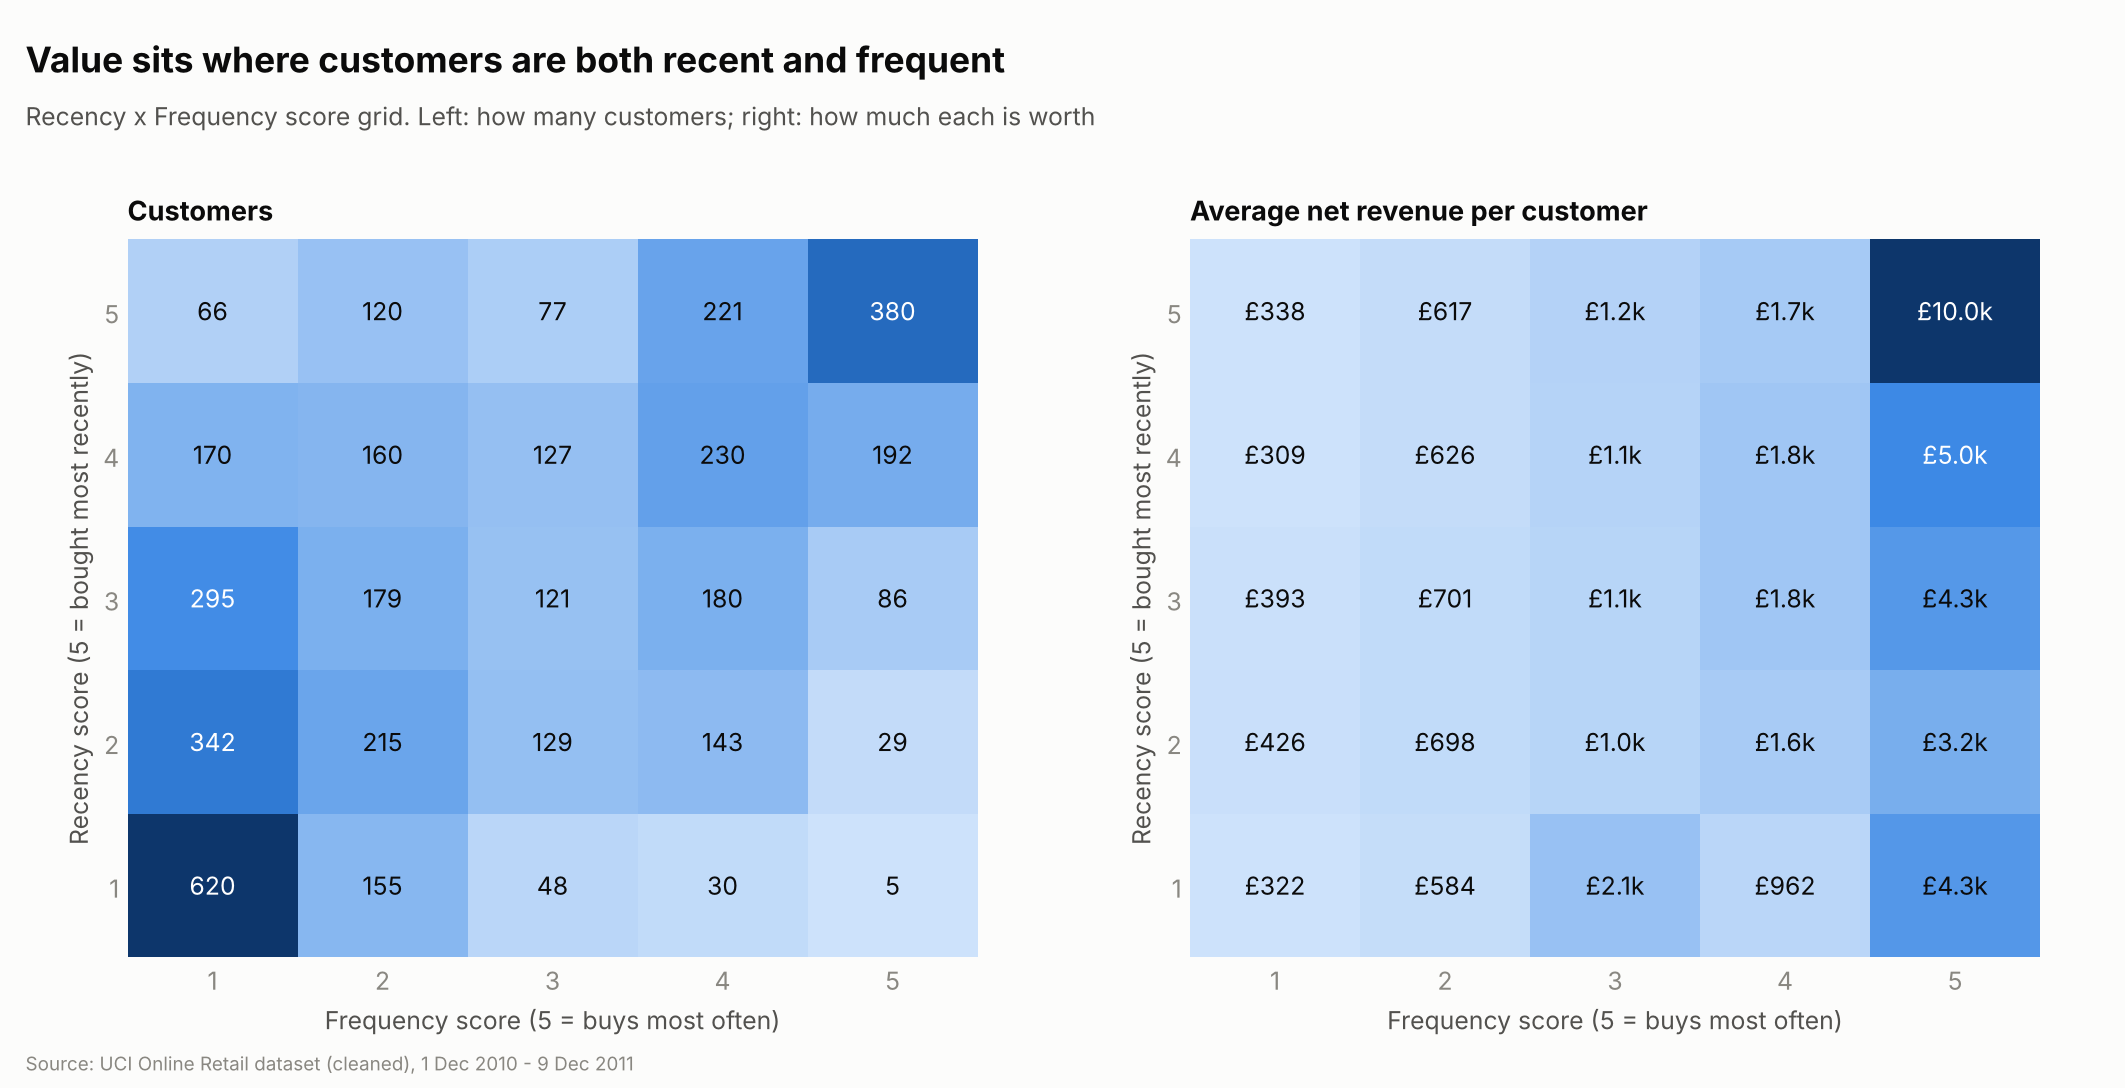

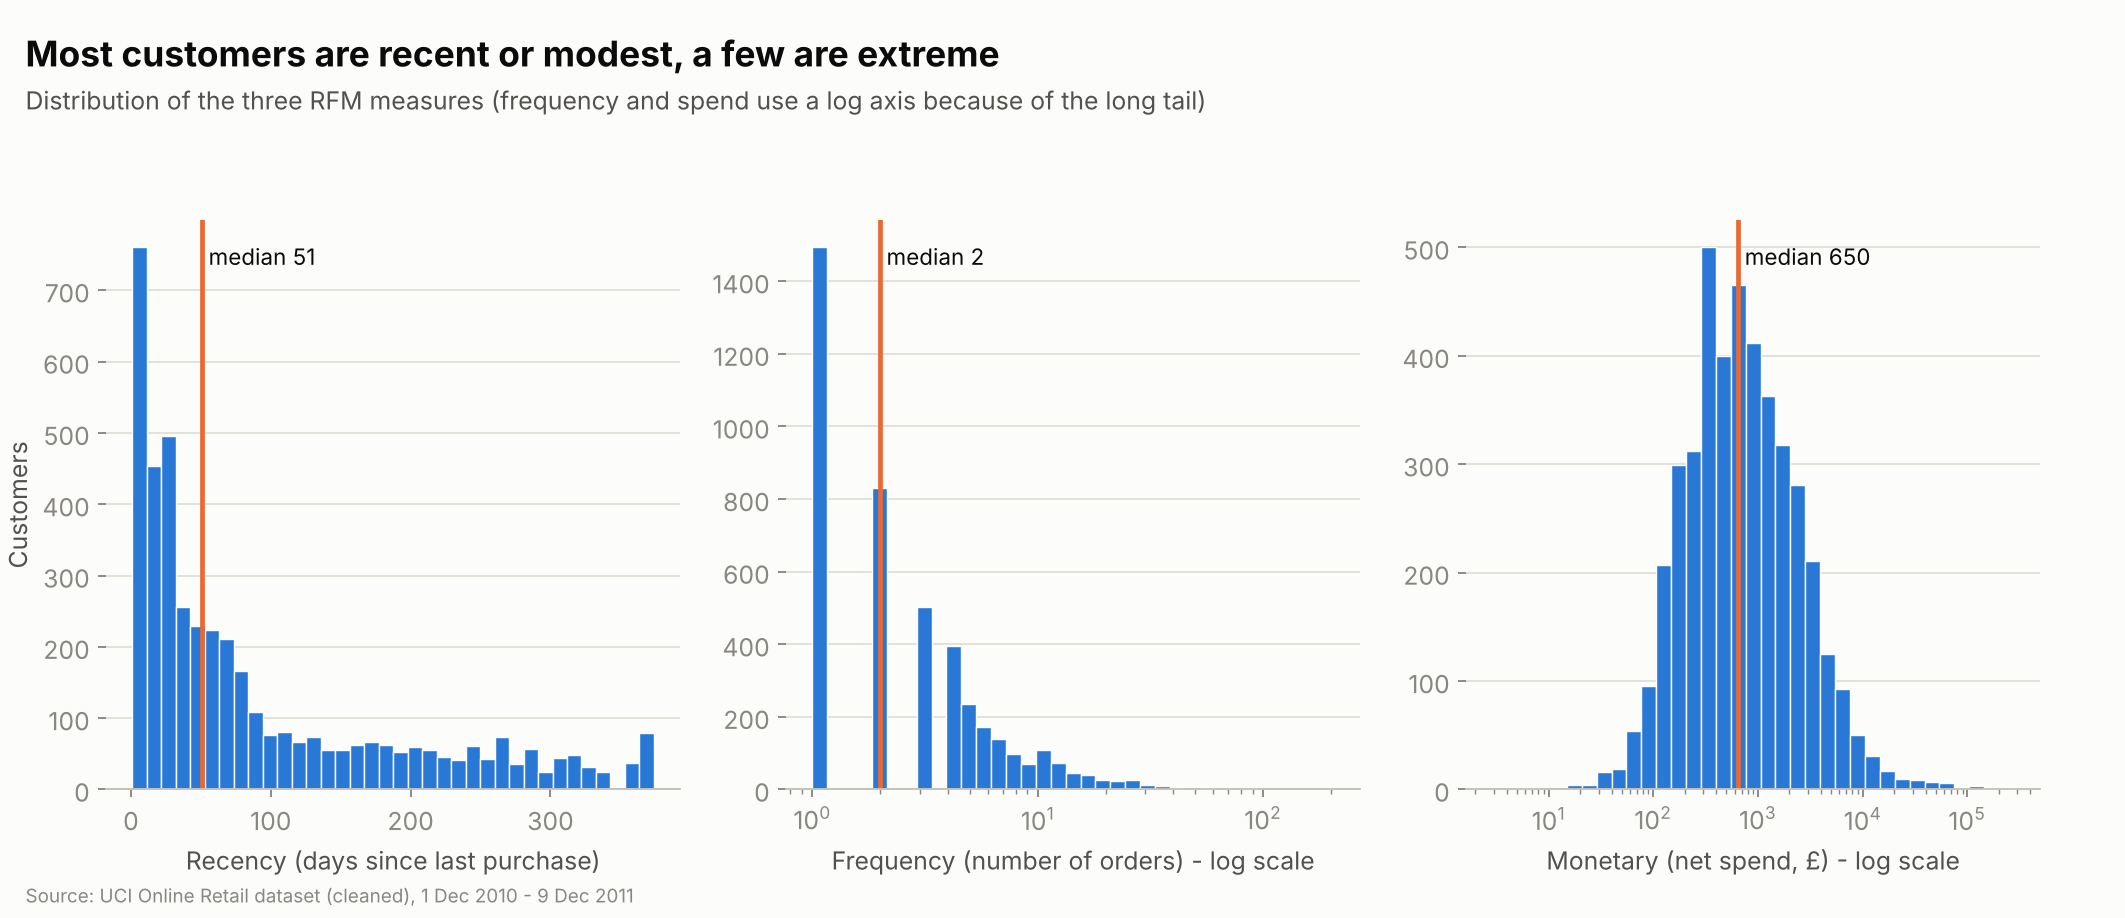

,rank,CustomerID,country,segment,net_revenue,frequency,recency_days,avg_order_value,return_rate_pct,share_of_net_revenue_pct
1689,1,14646,Netherlands,Champions,"278,778.02",72,2,"3,876.92",0.13,3.37
4197,2,18102,United Kingdom,Champions,"259,657.30",60,1,"4,327.62",0.00,3.14
3725,3,17450,United Kingdom,Champions,"189,575.53",46,9,"4,225.89",2.48,2.29
1879,4,14911,EIRE,Champions,"128,768.24",198,2,687.69,5.43,1.56
55,5,12415,Australia,Champions,"123,638.18",20,25,"6,228.23",0.74,1.50
1333,6,14156,EIRE,Champions,"113,685.77",54,10,"2,158.52",2.47,1.37
3768,7,17511,United Kingdom,Champions,"88,138.20",31,3,"2,937.50",3.21,1.07
3174,8,16684,United Kingdom,Champions,"65,920.12",28,5,"2,380.48",1.10,0.80
996,9,13694,United Kingdom,Champions,"62,961.54",50,4,"1,300.79",3.20,0.76
2700,10,16029,United Kingdom,Loyal Customers,"60,369.93",62,39,"1,172.71",16.97,0.73


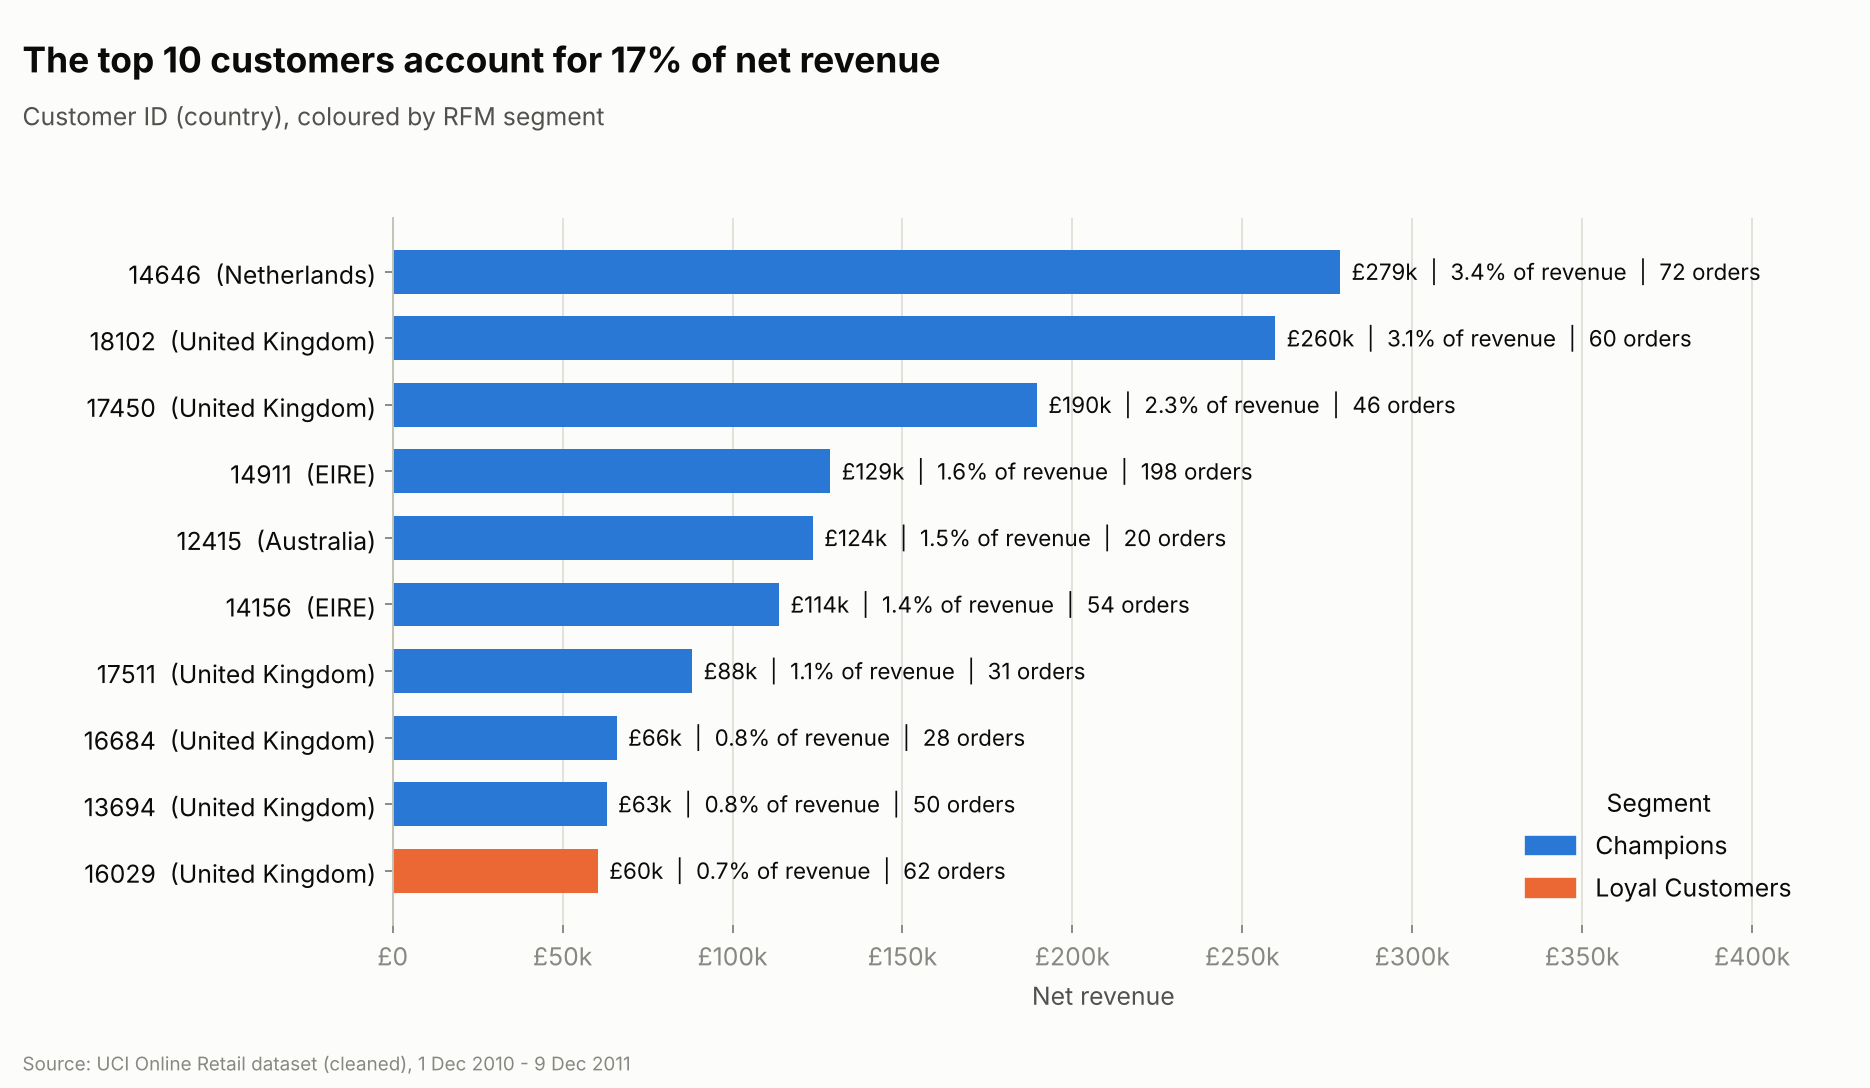

In [20]:
viz.rfm_heatmap(seg, VIZ)
display(Image(filename=str(VIZ / "06_rfm_heatmap.png")))
viz.rfm_distributions(pop, VIZ)
display(Image(filename=str(VIZ / "07_rfm_distributions.png")))
top = cm.top_customers(seg, 10)
display(top)
viz.top_customers_chart(top, VIZ)
display(Image(filename=str(VIZ / "08_top10_customers.png")))

### 5.2 Do the segments mean anything? A back-test
Segments are only useful if they predict behaviour. We rebuild the segments using **only data before 11 Sep 2011** and then look at what those customers did in the following 90 days (which the segmentation never saw).

Segments built with data before 2011-09-11 - outcome window up to 2011-12-10


,segment,customers,repurchase_rate_pct,avg_future_revenue,total_future_revenue,pct_of_future_revenue
0,Champions,885,83.62,"2,033.05","1,799,251.99",64.40
1,Loyal Customers,674,64.84,532.05,"358,598.70",12.84
2,Potential Loyalists,216,44.91,319.05,"68,914.41",2.47
3,New Customers,242,45.04,256.68,"62,115.43",2.22
4,At Risk,331,46.53,275.29,"91,119.46",3.26
5,Can't Lose Them,106,67.92,675.44,"71,596.98",2.56
6,Hibernating,905,33.92,377.97,"342,059.81",12.24


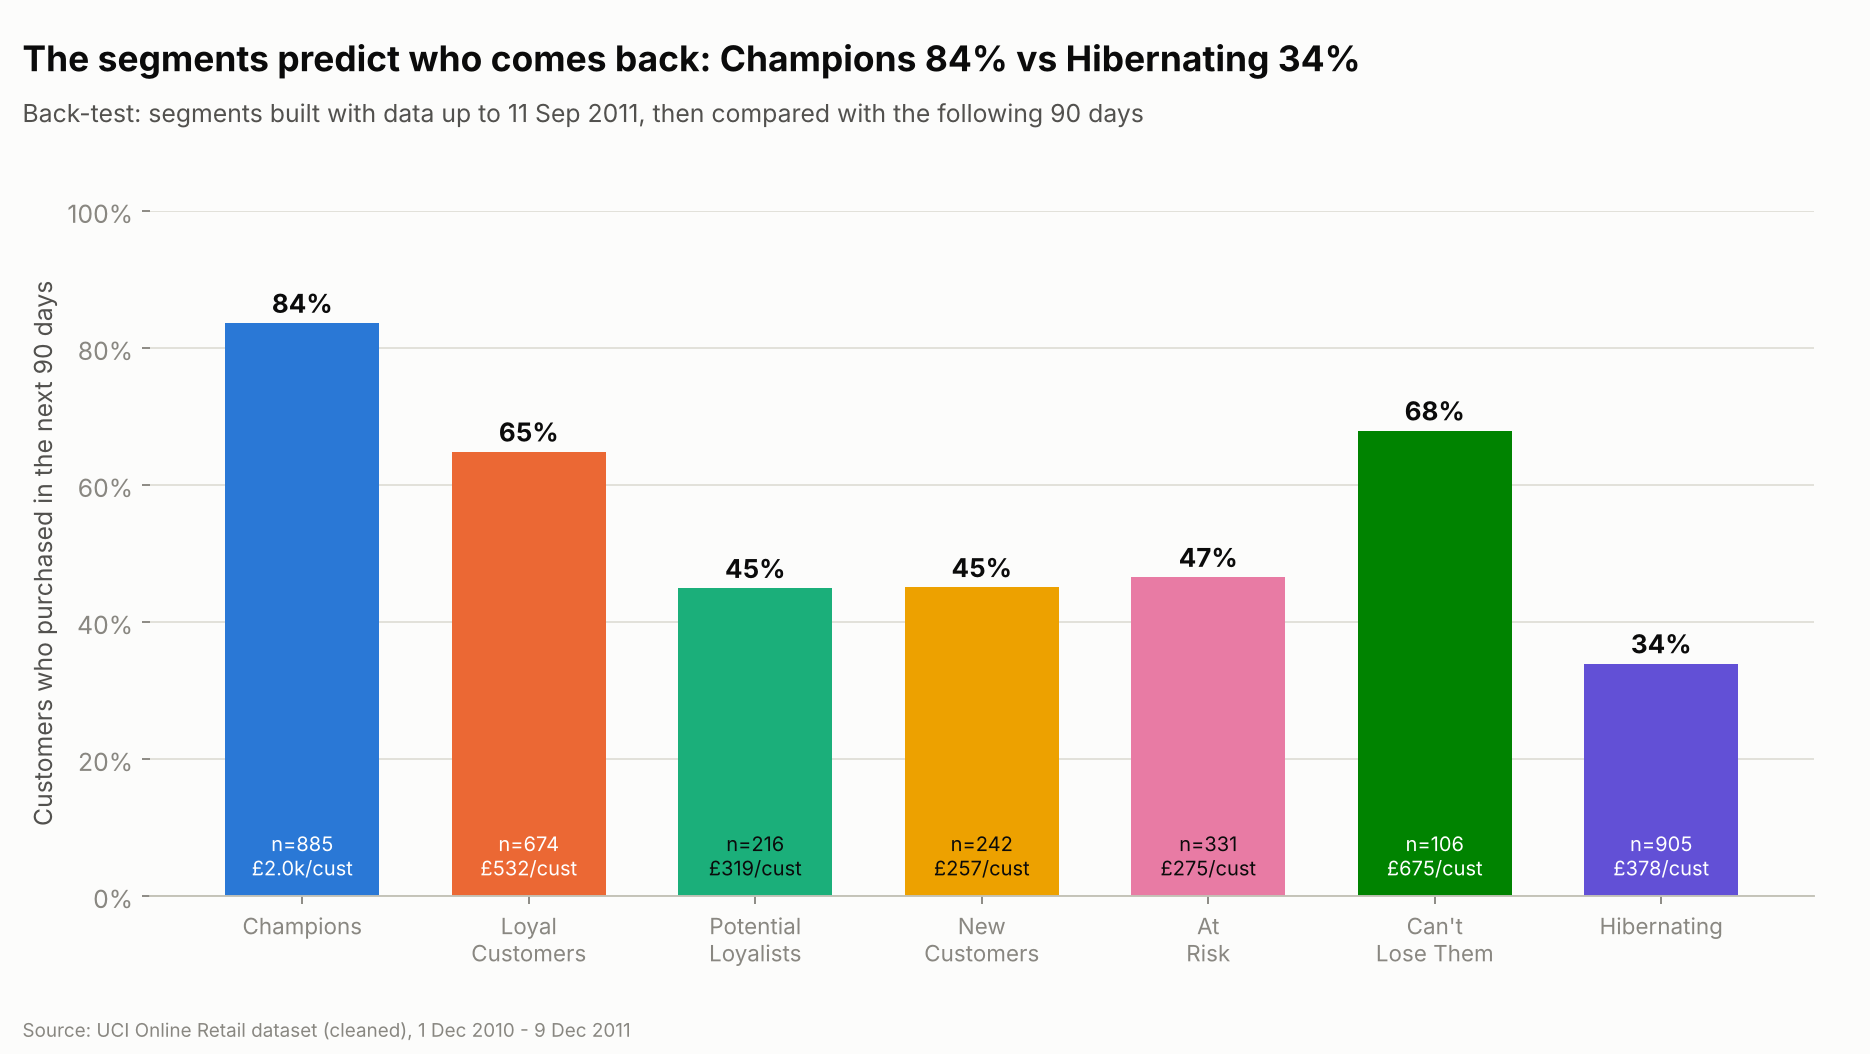

In [21]:
bt = ra.backtest_segments(sales, returns, holdout_days=90)
print("Segments built with data before", bt.attrs["cutoff"].date(), "- outcome window up to", bt.attrs["end"].date())
display(bt)
viz.backtest_chart(bt, VIZ)
display(Image(filename=str(VIZ / "16_segment_backtest.png")))

Champions come back far more often than Hibernating customers, with At Risk and Can't Lose Them in between, as the definitions predict. The segment boundaries are therefore informative; they are not perfect predictors (see Limitations in the README).

## 6. Business insights
Every number below is generated from the tables above.

In [22]:
insights = ins.build_insights(kpis, seg, summary, conc, rv, bt, monthly, country,
                              float(gaps.median()), repeat90, cohort_avg, weekday, hour)
for i, it in enumerate(insights, 1):
    display(Markdown(f"**{i}. {it['title']}**  \n*Evidence:* {it['evidence']}  \n*Meaning:* {it['interpretation']}  \n*Recommendation:* {it['recommendation']}"))

**1. Value comes from how often customers buy, not from how much they put in one basket**  
*Evidence:* Champions place 10.7 orders on average against 1.3 for Hibernating customers, but their average order is similar (£419 vs £356). Champions are 24% of customers and 67% of net revenue.  
*Meaning:* A customer becomes valuable by returning, so order frequency is the lever that separates the best customers from the rest.  
*Recommendation:* Measure and manage the second and third order. Reward order frequency (for example a reorder incentive or account-manager contact for customers on their 3rd to 5th order) rather than pushing larger baskets.

**2. A small group of customers carries the business**  
*Evidence:* The top 10% of customers deliver 60% of net revenue and the top 1% (43 customers) deliver 30%. 1,166 customers (27%) produce 80% of revenue; the bottom half adds only 8%. Gini coefficient: 0.71.  
*Meaning:* Losing even a few top accounts would be felt immediately in revenue, while the large base of small customers is cheap to lose but also adds little.  
*Recommendation:* Create a named-account programme for the top 1-5% (dedicated contact, early access to new products, service-level promises) and keep the long tail on low-cost, automated marketing.

**3. Customers who bought regularly and then went quiet are the best win-back target**  
*Evidence:* 384 customers (At Risk + Can't Lose Them) have spent £603k but have been inactive for 122-144 days on average; they used to place 3.5-5.9 orders. Can't Lose Them customers are worth £2,326 each on average, and in the back-test 68% of that group still bought in the next 90 days.  
*Meaning:* These customers have already proved they like the product. Their usual rhythm is a purchase every ~28 days (median), so a silence of four months or more is a clear warning sign, not normal behaviour.  
*Recommendation:* Run a personal win-back campaign for Can't Lose Them (call or personal email from an account manager, offer on their previously bought products) and an automated reminder sequence for At Risk. Trigger it when a customer passes about 90 days without an order.

**4. Getting a first-time buyer to order again is the biggest growth lever**  
*Evidence:* 35% of customers bought only once and contribute 6.5% of net revenue; repeat customers (average 6.0 orders) contribute 93.5%. Only 47% of customers place a second order within 90 days of their first, and in any later month roughly 24% of a monthly cohort is active.  
*Meaning:* Fewer than half of customers reorder within three months of their first purchase, and every monthly cohort loses most of its customers quickly, so the first 90 days decide whether a customer becomes a repeat buyer.  
*Recommendation:* Build a 90-day onboarding journey: a thank-you and product-care message after the first order, a reorder reminder at ~28 days, and a targeted offer at ~60 days for customers who have not yet reordered.

**5. New customers and Potential Loyalists are a large pipeline that is still worth little today**  
*Evidence:* New Customers + Potential Loyalists are 23% of customers (990) but only 5.9% of net revenue (average £551 for Potential Loyalists). Champions are worth £5,412 on average, 10 times more.  
*Meaning:* These customers bought recently but have not yet built a habit; if even a fraction move up to Loyal or Champions the revenue effect is large.  
*Recommendation:* Use 'next best product' recommendations and bundle offers to move them to a 3rd and 4th order. Track the share of this group that reaches Loyal Customers each quarter as a headline KPI.

**6. Hibernating customers are the largest group but low priority**  
*Evidence:* 31% of customers (1,332) are Hibernating: average 209 days since last order, 1.3 orders and £440 spent. In the back-test only 34% bought in the next 90 days.  
*Meaning:* Winning these customers back is possible but expensive relative to the value at stake.  
*Recommendation:* Include them only in low-cost, periodic campaigns (seasonal catalogue or email), and suppress them from paid channels. Use their purchase history to find which products brought them in and promote those.

**7. Revenue is strongly seasonal: September to November is the peak season**  
*Evidence:* September-November 2011 delivered £3.00M (38% of all full-month net revenue). November 2011 was the best month at £1.11M; the average of the other 2011 full months (Jan-Aug) was £548k. Order frequency is flat (about 1.3-1.6 orders per active customer per month), so the peak comes from more active customers (1,660 in the busiest month).  
*Meaning:* The peak is driven by more customers buying in the same month (average order value and orders per customer do not rise in the same way), which is consistent with customers stocking up for the holiday season.  
*Recommendation:* Plan stock, staffing and marketing around the autumn peak, and start retention campaigns in October so that new seasonal customers are contacted again before the quieter early-year months.

**8. The UK is the core market; a few overseas wholesalers are unusually valuable**  
*Evidence:* The UK holds 90% of customers and 82% of net revenue (£1,738 per customer). Highest revenue per customer outside the UK (countries with at least 3 customers): EIRE (£82k per customer, 3 customers), Netherlands (£31k per customer, 9 customers), Australia (£15k per customer, 9 customers).  
*Meaning:* Export revenue depends on a handful of accounts, which is both an opportunity (high value) and a risk (very small base).  
*Recommendation:* Treat the top overseas accounts as key accounts and test a small export wholesale offer in the countries where a few customers already spend heavily.

**9. Orders cluster mid-week and around midday**  
*Evidence:* Thursday is the busiest day (4,003 orders) and 12:00 is the busiest hour. There are no orders at all recorded on Saturdays.  
*Meaning:* Ordering during working hours on working days is consistent with a customer base that includes many business buyers.  
*Recommendation:* Send campaign emails early on Tuesday-Thursday mornings so they arrive before the midday ordering peak, and confirm whether the Saturday gap is a trading rule or a data-recording issue before drawing any conclusion from it.

## 7. Export deliverables

In [23]:
OUT.mkdir(exist_ok=True)
seg_out = seg[["CustomerID", "country", "first_purchase", "last_purchase", "recency_days", "frequency",
               "gross_revenue", "return_value", "net_revenue", "avg_order_value", "units", "distinct_products",
               "R_score", "F_score", "M_score", "RFM_score", "segment", "recommended_action"]].copy()
seg_out["segment"] = seg_out["segment"].astype(str)
seg_out = seg_out.sort_values("net_revenue", ascending=False)
seg_out.to_csv(OUT / "customer_segments.csv", index=False, date_format="%Y-%m-%d")
summary.assign(segment=summary["segment"].astype(str)).to_csv(OUT / "segment_summary.csv", index=False)

xl.export_workbook(
    OUT / "customer_analysis.xlsx", kpis=kpis, summary=summary, segment_rules=ra.SEGMENT_RULES, cuts=cuts,
    customers=seg_out.drop(columns=["recommended_action"]).assign(
        action=seg_out["recommended_action"]), monthly=monthly, cohort=ret, top=top, products=products, country=country,
    backtest=bt, clean_log=result.log, quality=result.quality_report, insights=insights, excluded_customers=no_value)

results = {
    "kpis": kpis, "concentration": conc, "repeat_within_90": repeat90, "repeat_within_60": repeat60,
    "gap_median_days": float(gaps.median()), "cohort_avg_pct": cohort_avg,
    "snapshot_date": str(snapshot.date()), "backtest_cutoff": str(bt.attrs["cutoff"].date()),
    "rfm_customers": int(len(pop)), "unscored_customers": int(len(no_value)),
    "segments": summary.assign(segment=summary["segment"].astype(str)).to_dict(orient="records"),
    "backtest": bt.assign(segment=bt["segment"].astype(str)).to_dict(orient="records"),
    "cut_points": cuts.to_dict(orient="records"),
    "cleaning_log": result.log.to_dict(orient="records"),
    "quality_report": result.quality_report.to_dict(orient="records"),
    "insights": insights,
    "top_customers": top.assign(segment=top["segment"].astype(str)).to_dict(orient="records"),
    "monthly": monthly.to_dict(orient="records"),
    "frequency_distribution": fd.assign(orders=fd["orders"].astype(str)).to_dict(orient="records"),
    "repeat_vs_onetime": rv.to_dict(orient="records"),
    "countries": country.head(10).to_dict(orient="records"),
    "products": products.head(10)[["StockCode", "description", "net_revenue", "net_units", "customers"]].to_dict(orient="records"),
    "weekday": weekday.to_dict(orient="records"),
    "peak_hour": int(hour.loc[hour["orders"].idxmax(), "hour"]),
}
with open(OUT / "analysis_results.json", "w", encoding="utf-8") as fh:
    json.dump(results, fh, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Saved:", *[p.name for p in sorted(OUT.iterdir())], sep="\n  ")

Saved:
  analysis_results.json
  customer_analysis.xlsx
  customer_segments.csv
  segment_summary.csv


## 8. Independent checks
The key totals are recomputed from the **raw file** with a different, deliberately simple method (plain filters, no helper modules) and compared with the pipeline.

In [24]:
r0 = pd.read_csv(ROOT / "data" / "raw" / "online_retail_raw.csv")
r0 = r0.drop_duplicates()
r0 = r0[r0["CustomerID"].notna() & (r0["UnitPrice"] > 0) & ~r0["StockCode"].astype(str).str.upper().isin(dc.NON_PRODUCT_CODES)]
r0["rev"] = r0["Quantity"] * r0["UnitPrice"]
is_c = r0["InvoiceNo"].astype(str).str.startswith("C")
chk = {
    "gross revenue": (r0.loc[~is_c, "rev"].sum(), kpis["gross_revenue"]),
    "returns value": (-r0.loc[is_c, "rev"].sum(), kpis["returns_value"]),
    "net revenue": (r0["rev"].sum(), kpis["net_revenue"]),
    "orders": (r0.loc[~is_c, "InvoiceNo"].nunique(), kpis["orders"]),
    "customers with a sale": (r0.loc[~is_c, "CustomerID"].nunique(), kpis["customers"]),
}
rows = []
for k, (a, b) in chk.items():
    rows.append({"check": k, "independent": a, "pipeline": b, "match": bool(abs(a - b) < 0.5)})
    assert abs(a - b) < 0.5, f"{k} mismatch"
display(pd.DataFrame(rows))

,check,independent,pipeline,match
0,gross revenue,"8,737,227.64","8,737,227.64",True
1,returns value,"471,750.71","471,750.71",True
2,net revenue,"8,265,476.93","8,265,476.93",True
3,orders,"18,402.00","18,402.00",True
4,customers with a sale,"4,334.00","4,334.00",True


In [25]:
assert abs(summary["net_revenue"].sum() - (cust.loc[cust["net_revenue"] > 0, "net_revenue"].sum())) < 0.5
assert summary["customers"].sum() == len(pop)
assert abs(summary["pct_customers"].sum() - 100) < 0.1 and abs(summary["pct_revenue"].sum() - 100) < 0.1
assert seg_out["CustomerID"].is_unique
assert pop["recency_days"].min() >= 1
assert set(seg_out["segment"]) <= set(ra.SEGMENT_ORDER)
tbl = pd.read_excel(OUT / "customer_analysis.xlsx", sheet_name="Customer_Segments")
assert len(tbl) == len(seg_out) and abs(tbl["net_revenue"].sum() - seg_out["net_revenue"].sum()) < 1
print("All checks passed: pipeline totals match the independent recomputation, shares add to 100%, Excel matches the CSV.")

All checks passed: pipeline totals match the independent recomputation, shares add to 100%, Excel matches the CSV.
